# The Kalman Filter — Interactive Companion to the Slides

**ELG 5218 — Uncertainty Evaluation in Engineering Measurements and Machine Learning** · Miodrag Bolić, University of Ottawa

This notebook contains only the examples that appear in the *Kalman Filter* slides, in the same order and under the same slide titles. Each example consists of:

1. **⚙️ Parameters** — values you can change (Colab shows them as form fields),
2. **▶ Run** — hidden code; run the cell to get the animation or plot,
3. **🔎 / 🎛️ / 💡** — what we see, what changes when you change the parameters, and why.

**How to use:** run the Setup cell first (or *Run all*, about 2 minutes). To experiment, change a value in a ⚙️ cell, run it, then run the ▶ cell below it.

**Notation (as in the slides):** state $\mathbf z_t$, measurement $\mathbf y_t$; prediction $\boldsymbol\mu_{t|t-1},\boldsymbol\Sigma_{t|t-1}$; posterior $\boldsymbol\mu_{t|t},\boldsymbol\Sigma_{t|t}$; predicted measurement $\hat{\mathbf y}_t$ with covariance $\mathbf S_t$; innovation $\tilde{\mathbf y}_t=\mathbf y_t-\hat{\mathbf y}_t$; gain $\mathbf K_t$. Scalar case: $\sigma^2_{t|t-1}$, $\sigma^2_{t|t}$, noise variances $q_t$, $r_t$.

**Colours:** <span style="color:#1f77b4">**blue = prediction**</span>, <span style="color:#d62728">**red = measurement**</span>, <span style="color:#2ca02c">**green = posterior**</span>, **black = truth**.

| Slide section | Examples in this notebook |
|---|---|
| 1. Introduction | The filtering problem |
| 2. Bayesian filtering | One predict–update cycle |
| 4. The 1D Kalman filter | A worked step · Tracking the robot |
| 5. Understanding the covariance matrix | Uncertainty ellipses · What prediction and update do to $\boldsymbol\Sigma$ |
| 6. Understanding the Kalman gain | Minimum-variance blend · Relative uncertainty · Regression slope · Misconception · Gain evolution |
| 7. Tuning and failure modes | $\boldsymbol\Sigma_0$ and $\boldsymbol\mu_0$ · $\mathbf R_t$ and $\mathbf Q_t$ · Divergence |
| 8. Examples | 2D constant-velocity tracking · Sensor fusion |

(Section 3 of the slides, *From the Bayesian filter to the Kalman filter*, is pure derivation and has no simulation.)

In [1]:
#@title 🔧 Setup — run this cell first (imports, Kalman filter class, plotting helpers)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import Rectangle
from scipy.stats import norm, chi2
from IPython.display import HTML, display
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 80
plt.rcParams['animation.embed_limit'] = 80   # MB
np.random.seed(42)

try:
    import ipywidgets as widgets
    from ipywidgets import interact, FloatSlider, FloatLogSlider, IntSlider
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets not installed: animations work, sliders are disabled (pip install ipywidgets)")

C_PRIOR, C_LIK, C_POST, C_TRUE = 'tab:blue', 'tab:red', 'tab:green', 'black'
_PAL = ['tab:orange', 'tab:purple', 'tab:cyan', 'tab:olive', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:blue']
def palette(n):
    return [_PAL[i % len(_PAL)] for i in range(n)]

def show_anim(anim):
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode='once'))

def gauss(x, mu, var):
    return norm.pdf(x, mu, np.sqrt(max(var, 1e-6)))

def peak(var):
    return 1/np.sqrt(2*np.pi*max(var, 1e-6))

def ellipse_xy(mean, cov, n_std=2.0, n=120):
    th = np.linspace(0, 2*np.pi, n)
    vals, vecs = np.linalg.eigh(cov)
    vals = np.maximum(vals, 0)
    pts = vecs @ (n_std*np.sqrt(vals)[:, None]*np.vstack([np.cos(th), np.sin(th)]))
    return np.asarray(mean)[:, None] + pts

def kf_1d(y, F=1.0, H=1.0, q=0.04, r=0.25, mu0=0.0, sigma2_0=1.0, b=0.0):
    # Scalar Kalman filter exactly as on the slide "Kalman Filter: 1D Scalar Case".
    T = len(y)
    keys = ['mu_pred', 's2_pred', 'y_hat', 'S', 'K', 'innov', 'mu_filt', 's2_filt']
    out = {k: np.zeros(T) for k in keys}
    mu, s2 = mu0, sigma2_0
    for t in range(T):
        mu_p = F*mu + b; s2_p = F*s2*F + q
        y_hat = H*mu_p; S = H*s2_p*H + r; K = s2_p*H/S
        innov = y[t] - y_hat
        mu = mu_p + K*innov; s2 = (1 - K*H)*s2_p
        for k, v in zip(keys, [mu_p, s2_p, y_hat, S, K, innov, mu, s2]):
            out[k][t] = v
    return out

rmse = lambda a, b: np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2))

class KalmanFilter:
    """Kalman Filter implementation following Murphy's notation"""

    def __init__(self, F, H, Q, R, B=None, b=None, D=None, d=None):
        """
        Initialize Kalman Filter

        Parameters:
        -----------
        F : ndarray (n_z, n_z)
            State transition matrix
        H : ndarray (n_y, n_z)
            Observation matrix
        Q : ndarray (n_z, n_z)
            Process noise covariance
        R : ndarray (n_y, n_y)
            Measurement noise covariance
        B : ndarray (n_z, n_u), optional
            Control input matrix
        b : ndarray (n_z,), optional
            State bias
        D : ndarray (n_y, n_u), optional
            Control observation matrix
        d : ndarray (n_y,), optional
            Observation bias
        """
        self.F = F
        self.H = H
        self.Q = Q
        self.R = R
        self.B = B if B is not None else np.zeros((F.shape[0], 1))
        self.b = b if b is not None else np.zeros(F.shape[0])
        self.D = D if D is not None else np.zeros((H.shape[0], 1))
        self.d = d if d is not None else np.zeros(H.shape[0])

        self.n_z = F.shape[0]
        self.n_y = H.shape[0]

    def predict(self, mu_prev, Sigma_prev, u=None):
        """
        Prediction step (time update)

        Returns: mu_pred, Sigma_pred
        """
        if u is None:
            u = np.zeros(self.B.shape[1])

        # Equation 8.23 from Murphy
        mu_pred = self.F @ mu_prev + self.B @ u + self.b

        # Equation 8.24 from Murphy
        Sigma_pred = self.F @ Sigma_prev @ self.F.T + self.Q

        return mu_pred, Sigma_pred

    def update(self, mu_pred, Sigma_pred, y, u=None):
        """
        Update step (measurement update)

        Returns: mu_upd, Sigma_upd, K (Kalman gain), innovation
        """
        if u is None:
            u = np.zeros(self.D.shape[1])

        # Predicted observation (Equation 8.26)
        y_hat = self.H @ mu_pred + self.D @ u + self.d

        # Innovation (residual)
        innovation = y - y_hat

        # Innovation covariance (Equation 8.27)
        S = self.H @ Sigma_pred @ self.H.T + self.R

        # Kalman gain (Equation 8.28)
        K = Sigma_pred @ self.H.T @ np.linalg.inv(S)

        # Updated state mean (Equation 8.29)
        mu_upd = mu_pred + K @ innovation

        # Updated state covariance (Equation 8.30)
        Sigma_upd = Sigma_pred - K @ self.H @ Sigma_pred

        return mu_upd, Sigma_upd, K, innovation

    def filter(self, y_seq, u_seq=None, mu_0=None, Sigma_0=None):
        """
        Run Kalman filter on sequence of observations

        Parameters:
        -----------
        y_seq : ndarray (T, n_y)
            Sequence of observations
        u_seq : ndarray (T, n_u), optional
            Sequence of control inputs
        mu_0 : ndarray (n_z,), optional
            Initial state mean
        Sigma_0 : ndarray (n_z, n_z), optional
            Initial state covariance

        Returns:
        --------
        mu_filtered : ndarray (T, n_z)
            Filtered state means
        Sigma_filtered : ndarray (T, n_z, n_z)
            Filtered state covariances
        mu_predicted : ndarray (T, n_z)
            Predicted state means
        Sigma_predicted : ndarray (T, n_z, n_z)
            Predicted state covariances
        """
        T = len(y_seq)

        if mu_0 is None:
            mu_0 = np.zeros(self.n_z)
        if Sigma_0 is None:
            Sigma_0 = np.eye(self.n_z)
        if u_seq is None:
            u_seq = [None] * T

        # Storage
        mu_filtered = np.zeros((T, self.n_z))
        Sigma_filtered = np.zeros((T, self.n_z, self.n_z))
        mu_predicted = np.zeros((T, self.n_z))
        Sigma_predicted = np.zeros((T, self.n_z, self.n_z))

        # Initial state
        mu_prev = mu_0
        Sigma_prev = Sigma_0

        for t in range(T):
            # Predict
            mu_pred, Sigma_pred = self.predict(mu_prev, Sigma_prev, u_seq[t])
            mu_predicted[t] = mu_pred
            Sigma_predicted[t] = Sigma_pred

            # Update
            mu_upd, Sigma_upd, K, innov = self.update(mu_pred, Sigma_pred, y_seq[t], u_seq[t])
            mu_filtered[t] = mu_upd
            Sigma_filtered[t] = Sigma_upd

            # Store for next iteration
            mu_prev = mu_upd
            Sigma_prev = Sigma_upd

        return mu_filtered, Sigma_filtered, mu_predicted, Sigma_predicted



def run_kf(kf, ys, mu0, Sig0):
    # Run the KalmanFilter class and keep everything we plot (incl. S_t)
    T = len(ys); nz = kf.n_z; ny = kf.n_y
    out = dict(mu_pred=np.zeros((T, nz)), Sig_pred=np.zeros((T, nz, nz)), mu_filt=np.zeros((T, nz)),
               Sig_filt=np.zeros((T, nz, nz)), K=np.zeros((T, nz, ny)), innov=np.zeros((T, ny)), S=np.zeros((T, ny, ny)))
    mu, Sig = mu0, Sig0
    for t in range(T):
        mp, Sp = kf.predict(mu, Sig)
        mu, Sig, K, inn = kf.update(mp, Sp, np.atleast_1d(ys[t]))
        for k, v in zip(['mu_pred', 'Sig_pred', 'mu_filt', 'Sig_filt', 'K', 'innov'], [mp, Sp, mu, Sig, K, inn]):
            out[k][t] = v
        out['S'][t] = kf.H @ Sp @ kf.H.T + kf.R
    return out

def maneuver_scenario(T=80, r=4.0, seed=8, t_maneuver=30, v_before=1.0, v_after=-1.5):
    # 1D target: constant velocity, then the velocity changes over 6 steps (a manoeuvre)
    rng = np.random.default_rng(seed)
    vel = np.full(T, float(v_before))
    t1, t2 = min(t_maneuver, T), min(t_maneuver + 6, T)
    vel[t1:t2] = np.linspace(v_before, v_after, 6)[:t2 - t1]; vel[t2:] = v_after
    pos = np.cumsum(vel) + 0.05*np.cumsum(rng.standard_normal(T))
    y = pos + np.sqrt(r)*rng.standard_normal(T)
    return pos, vel, y

def animate_comparison(tt, z_true, y, ests, gains, labels, colors, title, gain_label='$K_t$',
                       mid=None, frame_step=1, ylabel='position', legend_loc='upper left'):
    n_ax = 3 if mid else 2
    hr = [2, 1.3, 1] if mid else [2, 1]
    fig, axs = plt.subplots(n_ax, 1, figsize=(10, 7.5 if mid else 6.3), sharex=True, gridspec_kw={'height_ratios': hr})
    ax1, axg = axs[0], axs[-1]
    allv = np.concatenate([y[np.isfinite(y)], z_true] + list(ests))
    pad = 0.08*(allv.max() - allv.min() + 1e-9)
    top = 4*pad if legend_loc.startswith('upper') else pad
    bot = 4*pad if legend_loc.startswith('lower') else pad
    ax1.set_xlim(tt[0] - 0.5, tt[-1] + 0.5); ax1.set_ylim(allv.min() - bot, allv.max() + top); ax1.set_ylabel(ylabel)
    l_true, = ax1.plot([], [], color=C_TRUE, lw=2, label='truth $z_t$')
    l_meas, = ax1.plot([], [], '.', color=C_LIK, alpha=0.55, label='$y_t$')
    l_est = [ax1.plot([], [], color=c, lw=2, label=lab)[0] for c, lab in zip(colors, labels)]
    ax1.legend(loc=legend_loc, fontsize=9); ax1.set_title(title, fontsize=11)
    l_mid = []
    if mid:
        axm = axs[1]; tr, es, yl = mid
        allm = np.concatenate([tr] + list(es)); pm = 0.1*(allm.max() - allm.min() + 1e-9)
        axm.set_ylim(allm.min() - pm, allm.max() + pm); axm.set_ylabel(yl)
        l_mid = [axm.plot([], [], color=C_TRUE, lw=2)[0]] + [axm.plot([], [], color=c, lw=2)[0] for c in colors]
    axg.set_ylim(0, 1.08*max(np.max(g) for g in gains) + 1e-3)
    axg.set_ylabel(gain_label); axg.set_xlabel('$t$')
    l_gain = [axg.plot([], [], color=c, lw=2)[0] for c in colors]
    T = len(tt)
    frames = list(range(1, T + 1, max(1, frame_step))) + [T]*10

    def update(k):
        n = frames[k]
        l_true.set_data(tt[:n], z_true[:n]); l_meas.set_data(tt[:n], y[:n])
        for l, e in zip(l_est, ests): l.set_data(tt[:n], e[:n])
        for l, g in zip(l_gain, gains): l.set_data(tt[:n], g[:n])
        if mid:
            l_mid[0].set_data(tt[:n], mid[0][:n])
            for l, e in zip(l_mid[1:], mid[1]): l.set_data(tt[:n], e[:n])
        return [l_true, l_meas] + l_est + l_gain + l_mid

    return show_anim(animation.FuncAnimation(fig, update, frames=len(frames), interval=110))

print('Setup done. Widgets available:', HAS_WIDGETS)

Setup done. Widgets available: True


---
# 1. Introduction
## The Filtering Problem
A robot moves in 1D: $z_t = z_{t-1} + v\,\Delta t + w_t$, $w_t\sim\mathcal N(0,q)$, and a GPS reports $y_t = z_t + v_t$, $v_t\sim\mathcal N(0,r)$. The same robot is used again in Section 4 (*Tracking the robot*), so changes made here carry over.

In [2]:
#@title ⚙️ Parameters — the robot and its GPS
#@markdown `T_rob`: number of time steps · `v_rob`: speed (position units per step)
#@markdown `q_rob`: process-noise variance (how irregular the motion is) · `r_rob`: GPS noise variance · `seed_rob`: random seed
T_rob = 40      #@param {type:"integer"}
v_rob = 0.5     #@param {type:"number"}
q_rob = 0.05    #@param {type:"number"}
r_rob = 1.0     #@param {type:"number"}
seed_rob = 7    #@param {type:"integer"}

In [3]:
#@title ▶ Run the simulation (code hidden; double-click to show)
rng = np.random.default_rng(seed_rob)
dt_rob = 1.0
z_rob = np.zeros(T_rob + 1)
for t in range(1, T_rob + 1):
    z_rob[t] = z_rob[t-1] + v_rob*dt_rob + np.sqrt(q_rob)*rng.standard_normal()
y_rob = z_rob + np.sqrt(r_rob)*rng.standard_normal(T_rob + 1)
y_rob[0] = np.nan
t_rob = np.arange(T_rob + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_xlim(0, T_rob); ax.set_ylim(np.nanmin(y_rob) - 1, np.nanmax(y_rob) + 1)
ax.set_xlabel('time $t$'); ax.set_ylabel('position')
l_true, = ax.plot([], [], '--', color=C_TRUE, lw=1.5, alpha=0.6, label=r'hidden state $z_t$ (unknown to the filter)')
l_meas, = ax.plot([], [], 'o', color=C_LIK, ms=5, label=r'GPS measurement $y_t$')
robot,  = ax.plot([], [], 's', color=C_TRUE, ms=12)
ax.legend(loc='upper left')
ttl = ax.set_title('')

def update(k):
    l_true.set_data(t_rob[:k+1], z_rob[:k+1]); l_meas.set_data(t_rob[1:k+1], y_rob[1:k+1])
    robot.set_data([t_rob[k]], [z_rob[k]])
    ttl.set_text(f'$t={k}$: the filter only sees the red dots. Where is the robot now?')
    return l_true, l_meas, robot, ttl

show_anim(animation.FuncAnimation(fig, update, frames=T_rob + 1, interval=150))

> **🔎 What we see.** The black dashed line is the true position, which no estimator can see. The red dots are what the GPS reports. They scatter around the truth, typically within $\pm2\sqrt{r}$ (about $\pm2$ units with the default $r=1$). Looking at a single dot, you cannot tell where the robot is. Looking at the cloud of dots, your eye already draws a smooth line through them — that is exactly what a filter does, but optimally and online.
>
> **🎛️ What changes when you change the parameters.**
> - **`r_rob` ↑** (e.g. 5): the dots spread much more; individual measurements become almost useless and averaging over time becomes essential.
> - **`r_rob` ↓** (e.g. 0.05): the dots sit on the truth; you hardly need a filter.
> - **`q_rob` ↑** (e.g. 1): the true path becomes jagged. The motion model "move by `v_rob` per step" is now a poor predictor, so we must rely more on the sensor.
> - **`v_rob`**: changes the slope. It is known to the filter (it is the term $b_t = v\Delta t$), so it does not make filtering harder.
> - **`seed_rob`**: a different random realisation with the same statistics.
>
> **💡 Why.** There are two imperfect sources of information. The **model** knows how the robot tends to move, but $q$ makes its predictions drift away from reality over time. The **sensor** sees where the robot is right now, but $r$ makes each reading noisy. The ratio of $q$ to $r$ decides which source deserves more trust. The rest of the lecture shows that the Kalman filter computes this trust exactly (the Kalman gain).

---
# 2. Bayesian Filtering
## One Predict–Update Cycle
Several predict → update cycles for the scalar model $z_t = z_{t-1} + b + w_t$, $y_t = z_t + v_t$: the previous posterior is shifted and widened (prediction), multiplied by the likelihood of the new measurement (update), and normalised.

**Predict before you play:** can the green posterior peak lie outside the blue and red peaks?

In [4]:
#@title ⚙️ Parameters — Bayesian predict–update cycles
#@markdown `mu_0`, `sigma2_0`: prior mean and variance of $z_0$ · `q`: process-noise variance · `r`: measurement-noise variance
#@markdown `b`: known drift per step · `n_cycles`: number of predict–update cycles · `seed`: random seed
mu_0 = 0.0       #@param {type:"number"}
sigma2_0 = 0.3   #@param {type:"number"}
q = 0.6          #@param {type:"number"}
r = 0.5          #@param {type:"number"}
b = 2.0          #@param {type:"number"}
n_cycles = 4     #@param {type:"integer"}
seed = 1         #@param {type:"integer"}

In [5]:
#@title ▶ Run the simulation (code hidden; double-click to show)
rng = np.random.default_rng(seed)
mu, s2 = mu_0, sigma2_0
z = mu_0 + np.sqrt(sigma2_0)*rng.standard_normal()
cycles = []
for t in range(1, n_cycles + 1):
    z = z + b + np.sqrt(q)*rng.standard_normal()
    y = z + np.sqrt(r)*rng.standard_normal()
    mu_p, s2_p = mu + b, s2 + q
    K = s2_p/(s2_p + r)
    mu_f, s2_f = mu_p + K*(y - mu_p), (1 - K)*s2_p
    cycles.append(dict(t=t, mu=mu, s2=s2, mu_p=mu_p, s2_p=s2_p, y=y, mu_f=mu_f, s2_f=s2_f, K=K))
    mu, s2 = mu_f, s2_f

centres = [mu_0] + [c['y'] for c in cycles] + [c['mu_p'] for c in cycles]
smax = max([sigma2_0, r] + [c['s2_p'] for c in cycles])
smin = min([sigma2_0, r] + [c['s2_f'] for c in cycles])
zz = np.linspace(min(centres) - 4*np.sqrt(smax), max(centres) + 4*np.sqrt(smax), 700)
nph = 10
frames = [(c, ph, i/(nph - 1)) for c in range(len(cycles)) for ph in range(3) for i in range(nph)]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.set_xlim(zz[0], zz[-1]); ax.set_ylim(0, 1.45*peak(smin))
ax.set_xlabel('$z$'); ax.set_ylabel('density')
old = [ax.plot([], [], color='0.6', lw=1, alpha=0.6)[0] for _ in cycles]
l_prev, = ax.plot([], [], '--', color=C_POST, alpha=0.6, lw=1.5, label=r'$p(z_{t-1}\mid y_{1:t-1})$')
l_pred, = ax.plot([], [], color=C_PRIOR, lw=2.5, label=r'$p(z_t\mid y_{1:t-1})$  predict')
l_lik,  = ax.plot([], [], color=C_LIK, lw=2, label=r'$p(y_t\mid z_t)$  likelihood')
l_post, = ax.plot([], [], color=C_POST, lw=3, label=r'$p(z_t\mid y_{1:t})$  update')
ax.legend(loc='upper right', fontsize=9)
ttl = ax.set_title('', fontsize=11)

def update(k):
    c, ph, lam = frames[k]
    C = cycles[c]
    for j, l in enumerate(old):
        if j < c: l.set_data(zz, gauss(zz, cycles[j]['mu_f'], cycles[j]['s2_f']))
        else:     l.set_data([], [])
    l_prev.set_data(zz, gauss(zz, C['mu'], C['s2']))
    l_lik.set_data([], []); l_post.set_data([], [])
    if ph == 0:
        l_pred.set_data(zz, gauss(zz, C['mu'] + lam*b, C['s2'] + lam*q))
        ttl.set_text(rf"$t={C['t']}$  PREDICT: shift by $b$, widen by $q$:  $\sigma^2_{{t|t-1}}={C['s2']:.2f}+{lam*q:.2f}$")
    else:
        l_pred.set_data(zz, gauss(zz, C['mu_p'], C['s2_p']))
        l_lik.set_data(zz, (lam if ph == 1 else 1.0)*gauss(zz, C['y'], r))
        if ph == 1:
            ttl.set_text(rf"$t={C['t']}$  MEASUREMENT $y_t={C['y']:.2f}$ arrives (variance $r={r}$)")
        else:
            m = (1 - lam)*C['mu_p'] + lam*C['mu_f']; v = (1 - lam)*C['s2_p'] + lam*C['s2_f']
            l_post.set_data(zz, gauss(zz, m, v))
            ttl.set_text(rf"$t={C['t']}$  UPDATE: prediction $\times$ likelihood, $K_t={C['K']:.2f}$, $\sigma^2_{{t|t}}={C['s2_f']:.2f}$")
    return old + [l_prev, l_pred, l_lik, l_post]

show_anim(animation.FuncAnimation(fig, update, frames=len(frames), interval=90))

> **🔎 What we see.** In every cycle the dashed green curve (yesterday's posterior) moves right by $b$ and becomes the wider blue prediction. Its variance grows by exactly $q$, as printed in the title. The red likelihood appears at the measurement, and the green posterior forms **between** blue and red, closer to whichever is narrower. The green curve is always narrower than both blue and red. After a few cycles the curves have the same width in every cycle, because the filter has reached a steady state.
>
> **🎛️ What changes when you change the parameters.**
> - **`q` ↑** (e.g. 3): the blue prediction becomes very wide, the gain rises to about 0.87, and the green posterior almost sits on the red measurement. With `q` = 30 it reaches 0.98.
> - **`r` ↑** (e.g. 5): the red likelihood becomes flat, the gain drops to about 0.3, and the posterior stays much closer to the prediction. With `r` = 50 the gain is about 0.1.
> - **`q` = `r`**: in steady state the gain settles at $K\approx0.62$, not 0.5. That is because $\sigma^2_{t|t-1} = \sigma^2_{t-1|t-1} + q > r$.
> - **`sigma2_0`**: matters mainly in the first cycle. Try 0.01 (very confident prior) or 10 (no idea): from cycle 2 or 3 onwards the curves look the same.
> - **`b`**: only shifts things. The drift is known, so it adds no uncertainty.
>
> **💡 Why.** For Gaussians the product “prediction × likelihood” is again Gaussian, with mean $\mu_{t|t} = (1-K_t)\,\mu_{t|t-1} + K_t\,y_t$ and $0\le K_t\le1$. That is a weighted average, so the posterior peak can **never** lie outside the two peaks. Its variance is $\sigma^2_{t|t} = \frac{\sigma^2_{t|t-1}\,r}{\sigma^2_{t|t-1}+r}$. This is smaller than both $\sigma^2_{t|t-1}$ and $r$: combining two independent pieces of information always reduces uncertainty. Prediction adds $q$ and update removes a fraction of the variance. When these balance, the filter reaches the steady state.

---
# 4. The One-Dimensional Kalman Filter
## 1D Kalman Filter: A Worked Step
Random walk $z_t=z_{t-1}+w_t$, $w_t\sim\mathcal N(0,q)$, measured as $y_t=z_t+v_t$, $v_t\sim\mathcal N(0,r)$. Defaults are the slide values ($\mu_{t-1|t-1}=2.0$, $\sigma^2_{t-1|t-1}=0.09$, $q=0.04$, $r=0.25$, $y_t=2.6$). The cell prints every quantity of one predict–update step and plots prediction, likelihood and posterior.

In [6]:
#@title ⚙️ Parameters — mini-example calculator
#@markdown Previous posterior `mu_prev`, `Sigma_prev`; noise variances `q`, `r`; new measurement `y_t`
mu_prev = 2.0      #@param {type:"number"}
Sigma_prev = 0.09  #@param {type:"number"}
q = 0.04           #@param {type:"number"}
r = 0.25           #@param {type:"number"}
y_t = 2.6          #@param {type:"number"}

    mu_{t|t-1} = 2.0000
 Sigma_{t|t-1} = 0.1300
       y_hat_t = 2.0000
    innovation = 0.6000
           S_t = 0.3800
           K_t = 0.3421
      mu_{t|t} = 2.2053
   Sigma_{t|t} = 0.0855


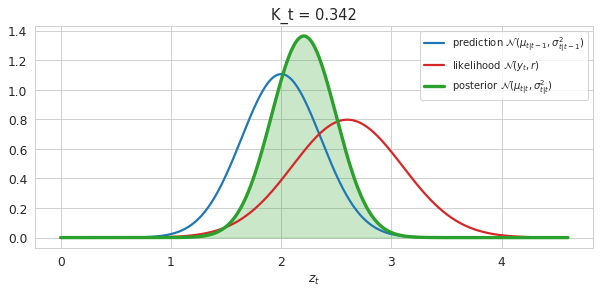

In [7]:
#@title ▶ Compute and plot one predict–update step (code hidden)
out = kf_1d(np.array([y_t]), q=q, r=r, mu0=mu_prev, sigma2_0=Sigma_prev)
for name, key in [('mu_{t|t-1}', 'mu_pred'), ('Sigma_{t|t-1}', 's2_pred'), ('y_hat_t', 'y_hat'),
                  ('innovation', 'innov'), ('S_t', 'S'), ('K_t', 'K'), ('mu_{t|t}', 'mu_filt'), ('Sigma_{t|t}', 's2_filt')]:
    print(f'{name:>14s} = {out[key][0]:.4f}')

zz_lo = min(out['mu_pred'][0], y_t) - 4*np.sqrt(max(out['s2_pred'][0], r))
zz_hi = max(out['mu_pred'][0], y_t) + 4*np.sqrt(max(out['s2_pred'][0], r))
zz = np.linspace(zz_lo, zz_hi, 600)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(zz, gauss(zz, out['mu_pred'][0], out['s2_pred'][0]), color=C_PRIOR, lw=2, label=r'prediction $\mathcal{N}(\mu_{t|t-1},\sigma^2_{t|t-1})$')
ax.plot(zz, gauss(zz, y_t, r), color=C_LIK, lw=2, label=r'likelihood $\mathcal{N}(y_t, r)$')
ax.fill_between(zz, gauss(zz, out['mu_filt'][0], out['s2_filt'][0]), color=C_POST, alpha=0.25)
ax.plot(zz, gauss(zz, out['mu_filt'][0], out['s2_filt'][0]), color=C_POST, lw=3, label=r'posterior $\mathcal{N}(\mu_{t|t},\sigma^2_{t|t})$')
ax.set_xlabel('$z_t$'); ax.legend(fontsize=9); ax.set_title(f"K_t = {out['K'][0]:.3f}")
plt.show()


> **🔎 What we see.** With the default inputs the printout matches the slide: $K_t=0.342$, $\mu_{t|t}=2.205$, $\sigma^2_{t|t}=0.0856$. In the plot the green posterior lies between the blue prediction and the red likelihood, closer to the narrower (blue) one, and it is narrower than both: $0.0856<\min(0.13,\,0.25)$.
>
> **🎛️ What changes when you change the parameters.**
> - **`y_t`** (try 1.0 or 5.0): the innovation and $\mu_{t|t}$ change; **$K_t$ and $\sigma^2_{t|t}$ stay exactly the same**, and the posterior keeps its width.
> - **`r` ↑** (e.g. 2.5): $K_t\approx0.05$; the posterior barely moves away from the prediction. **`r` ↓** (e.g. 0.01): $K_t\approx0.93$; the posterior sits on the measurement.
> - **`q` ↑** or **`Sigma_prev` ↑**: a less certain prediction, so a larger $K_t$.
>
> **💡 Why.** $K_t=\sigma^2_{t|t-1}/(\sigma^2_{t|t-1}+r)$ and $\sigma^2_{t|t}=(1-K_t)\sigma^2_{t|t-1}$ contain only variances, never the measured value; the data enter only through the innovation in the mean. This is the product of two Gaussians (slide *1D Shortcut*): precisions add, $1/\sigma^2_{t|t}=1/\sigma^2_{t|t-1}+1/r$, so the posterior is always narrower than both inputs.

## 1D Example: Tracking the Robot
The robot from Section 1: $F_t=1$, $b_t=v\Delta t$, $Q_t=q$, $H_t=1$, $R_t=r$. First the filter is run step by step (three frames per step: predict → measurement → update, with all numbers printed). The filter's `q_filter`, `r_filter` default to the robot's true values.

In [8]:
#@title ⚙️ Parameters — step-by-step Kalman filter on the robot
#@markdown `T_show`: number of time steps shown · `mu_0`, `sigma2_0`: prior on $z_0$
#@markdown `q_filter`, `r_filter`: noise variances *assumed by the filter* (default: the true robot values `q_rob`, `r_rob`)
T_show = 15         #@param {type:"integer"}
mu_0 = 0.0          #@param {type:"number"}
sigma2_0 = 1.0      #@param {type:"number"}
q_filter = q_rob    #@param {type:"raw"}
r_filter = r_rob    #@param {type:"raw"}

In [9]:
#@title ▶ Run the simulation (code hidden; double-click to show)
T_show = int(min(T_show, T_rob))
res = kf_1d(y_rob[1:T_show + 1], q=q_filter, r=r_filter, mu0=mu_0, sigma2_0=sigma2_0, b=v_rob*dt_rob)
frames = [(t, ph) for t in range(T_show) for ph in range(3)] + [(T_show - 1, 2)]*6
pmax = 1.15*max(peak(np.min(res['s2_filt'])), peak(r_filter), peak(np.min(res['s2_pred'])))

fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(2, 2, width_ratios=[2.2, 1], height_ratios=[1.2, 1], hspace=0.35, wspace=0.08)
ax1 = fig.add_subplot(gs[0, 0]); ax2 = fig.add_subplot(gs[1, 0]); axt = fig.add_subplot(gs[:, 1]); axt.axis('off')
allv = np.r_[z_rob[:T_show + 1], y_rob[1:T_show + 1], res['mu_pred'] + 2*np.sqrt(res['s2_pred']), res['mu_pred'] - 2*np.sqrt(res['s2_pred'])]
ax1.set_xlim(-0.5, T_show + 0.5); ax1.set_ylim(allv.min() - 1, allv.max() + 0.25*np.ptp(allv)); ax1.set_xlabel('$t$'); ax1.set_ylabel('position')
ax1.plot(t_rob[:T_show + 1], z_rob[:T_show + 1], '--', color=C_TRUE, alpha=0.4, label='truth $z_t$')
eb_pred = ax1.errorbar([], [], yerr=[], fmt='x', color=C_PRIOR, capsize=3, label=r'$\mu_{t|t-1}\pm2\sigma_{t|t-1}$')
eb_filt = ax1.errorbar([], [], yerr=[], fmt='o', color=C_POST, capsize=3, label=r'$\mu_{t|t}\pm2\sigma_{t|t}$')
l_meas, = ax1.plot([], [], 'o', mfc='none', color=C_LIK, label='$y_t$')
ax1.legend(loc='upper left', fontsize=9, ncol=2)
l_p, = ax2.plot([], [], color=C_PRIOR, lw=2.5, label='predict')
l_l, = ax2.plot([], [], color=C_LIK, lw=2, label='likelihood')
l_f, = ax2.plot([], [], color=C_POST, lw=3, label='posterior')
l_z  = ax2.axvline(0, color=C_TRUE, ls='--', alpha=0.5)
ax2.set_ylim(0, pmax); ax2.set_xlabel('$z_t$'); ax2.legend(loc='upper right', fontsize=9)
txt = axt.text(0.0, 1.0, '', va='top', fontsize=12, transform=axt.transAxes, linespacing=1.6)
ttl = ax1.set_title('')

def eb_set(eb, x, y, err):
    line, caps, (bars,) = eb
    line.set_data(x, y); bars.set_segments([[(xi, yi - e), (xi, yi + e)] for xi, yi, e in zip(x, y, err)])
    for c in caps: c.set_data([], [])

def update(k):
    t, ph = frames[k]
    tt = np.arange(1, t + 2)
    eb_set(eb_pred, tt - 0.15, res['mu_pred'][:t+1], 2*np.sqrt(res['s2_pred'][:t+1]))
    nf = t + 1 if ph == 2 else t
    eb_set(eb_filt, tt[:nf], res['mu_filt'][:nf], 2*np.sqrt(res['s2_filt'][:nf]))
    nm = t + 1 if ph >= 1 else t
    l_meas.set_data(tt[:nm], y_rob[1:nm + 1])
    mp, sp = res['mu_pred'][t], res['s2_pred'][t]
    prev_m = mu_0 if t == 0 else res['mu_filt'][t-1]; prev_s = sigma2_0 if t == 0 else res['s2_filt'][t-1]
    w = 4*np.sqrt(max(sp, r_filter))
    zz = np.linspace(mp - w, mp + w, 600); ax2.set_xlim(zz[0], zz[-1])
    l_p.set_data(zz, gauss(zz, mp, sp)); l_z.set_xdata([z_rob[t+1]]*2)
    if ph >= 1: l_l.set_data(zz, gauss(zz, y_rob[t+1], r_filter))
    else:       l_l.set_data([], [])
    if ph == 2: l_f.set_data(zz, gauss(zz, res['mu_filt'][t], res['s2_filt'][t]))
    else:       l_f.set_data([], [])
    lines = [rf'$t = {t+1}$', '', r'$\bf{Predict}$',
             rf'$\mu_{{t|t-1}} = {prev_m:.2f} + {v_rob*dt_rob:.2f} = {mp:.2f}$',
             rf'$\sigma^2_{{t|t-1}} = {prev_s:.3f} + {q_filter:.3f} = {sp:.3f}$']
    if ph >= 1:
        lines += ['', r'$\bf{Measurement}$', rf'$y_t = {y_rob[t+1]:.2f},\ \ \hat y_t = {res["y_hat"][t]:.2f}$',
                  rf'$\tilde y_t = y_t-\hat y_t = {res["innov"][t]:+.2f}$', rf'$S_t = \sigma^2_{{t|t-1}} + r_t = {res["S"][t]:.3f}$']
    if ph == 2:
        lines += ['', r'$\bf{Update}$', rf'$K_t = \sigma^2_{{t|t-1}}/S_t = {res["K"][t]:.3f}$',
                  rf'$\mu_{{t|t}} = {mp:.2f} + {res["K"][t]:.3f}\cdot({res["innov"][t]:+.2f}) = {res["mu_filt"][t]:.2f}$',
                  rf'$\sigma^2_{{t|t}} = (1-K_t)\,\sigma^2_{{t|t-1}} = {res["s2_filt"][t]:.3f}$']
    txt.set_text('\n'.join(lines))
    ttl.set_text(['PREDICT', 'MEASUREMENT ARRIVES', 'UPDATE'][ph] + f'   (t = {t+1})')
    return []

show_anim(animation.FuncAnimation(fig, update, frames=len(frames), interval=650))

> **🔎 What we see.** In the top panel, the blue predicted error bars are always longer than the green filtered ones, and each green estimate lands between the blue prediction and the red measurement. The error bars shrink during the first steps and then keep a constant length. In the text panel, $K_t$ falls from a large value at $t=1$ to a steady value (about 0.2 with the defaults) after a few steps. $\sigma^2_{t|t-1}$ and $\sigma^2_{t|t}$ also stop changing. In the bottom panel, the dashed black line (truth) is usually inside the green posterior.
>
> **🎛️ What changes when you change the parameters.**
> - **`sigma2_0` = 100**: at $t=1$, $K_1\approx1$ and the estimate jumps onto the first measurement. **`sigma2_0` = 0.001**: $K_1$ is tiny and the filter trusts its prior for several steps.
> - **`r_filter` = 0.05** (filter thinks the GPS is excellent): $K_t\approx0.6$–$0.8$, and the green points follow the noisy red dots.
> - **`r_filter` = 20**: $K_t\approx0.05$. The estimate follows the motion model and ignores the dots; error bars are small, but the estimate can sit far from the truth (overconfident).
> - **`q_filter` = 1**: the predictions are uncertain, so the gain stays high and the estimate tracks the measurements closely.
> - **`mu_0` = 10** (a wrong start): the error is visible at $t=1$ and disappears within a few steps (see Section 7, *Initial conditions*).
>
> **💡 Why.** $K_t = \sigma^2_{t|t-1}/(\sigma^2_{t|t-1}+r)$ is large when the prediction is uncertain relative to the sensor. At the start, $\sigma^2_{t|t-1} = \sigma_0^2 + q$ is dominated by the prior. After that, every update shrinks the variance by $(1-K_t)$ and every prediction adds $q$. When the two effects balance, $\sigma^2$ and $K_t$ reach a fixed point (Section 6, *Gain evolution*). When `q_filter` or `r_filter` differ from the true values, the filter still runs, but the error bars no longer describe the actual errors — they describe what the filter *believes*.

The complete run, as in the slide figure: estimate with its $\pm2\sigma_{t|t}$ band, and the evolution of $K_t$ and $\sigma^2_{t|t-1}$.

In [10]:
#@title ⚙️ Parameters — Example 1 filter settings
#@markdown `mu_0`, `sigma2_0`: prior · `q_filter`, `r_filter`: variances assumed by the filter (default: true robot values)
mu_0 = 0.0         #@param {type:"number"}
sigma2_0 = 1.0     #@param {type:"number"}
q_filter = q_rob   #@param {type:"raw"}
r_filter = r_rob   #@param {type:"raw"}

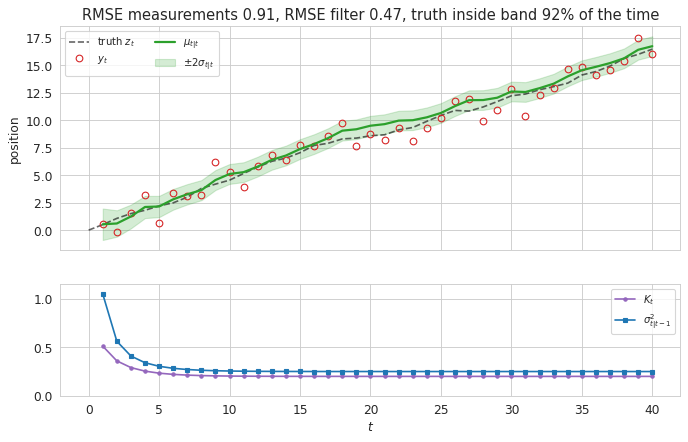

In [11]:
#@title ▶ Run the filter on the whole record (code hidden)
kf_ex1 = KalmanFilter(F=np.array([[1.0]]), H=np.array([[1.0]]), Q=np.array([[q_filter]]), R=np.array([[r_filter]]), b=np.array([v_rob*dt_rob]))
mu_f, Sig_f, mu_p, Sig_p = kf_ex1.filter(y_rob[1:, None], mu_0=np.array([mu_0]), Sigma_0=np.array([[sigma2_0]]))
res_full = kf_1d(y_rob[1:], q=q_filter, r=r_filter, mu0=mu_0, sigma2_0=sigma2_0, b=v_rob*dt_rob)
tt = t_rob[1:]; m, s = mu_f[:, 0], 2*np.sqrt(Sig_f[:, 0, 0])
inside = np.mean(np.abs(m - z_rob[1:]) <= s)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
a1.plot(t_rob, z_rob, '--', color=C_TRUE, alpha=0.6, label='truth $z_t$')
a1.plot(tt, y_rob[1:], 'o', color=C_LIK, mfc='none', label='$y_t$')
a1.plot(tt, m, color=C_POST, lw=2, label=r'$\mu_{t|t}$'); a1.fill_between(tt, m - s, m + s, color=C_POST, alpha=0.2, label=r'$\pm2\sigma_{t|t}$')
a1.set_ylabel('position'); a1.legend(loc='upper left', ncol=2, fontsize=9)
a1.set_title(f'RMSE measurements {rmse(y_rob[1:], z_rob[1:]):.2f}, RMSE filter {rmse(m, z_rob[1:]):.2f}, truth inside band {100*inside:.0f}% of the time')
a2.plot(tt, res_full['K'], 'o-', color='tab:purple', ms=3, label='$K_t$')
a2.plot(tt, res_full['s2_pred'], 's-', color=C_PRIOR, ms=3, label=r'$\sigma^2_{t|t-1}$')
a2.set_xlabel('$t$'); a2.legend(fontsize=9); a2.set_ylim(0, 1.1*max(1.0, res_full['s2_pred'].max()))
plt.show()


> **🔎 What we see.** **Step by step:** the blue predicted error bars are always longer than the green filtered ones, and each green estimate lands between the blue prediction and the red measurement. **Whole record:** the estimate is a smooth line through the measurements and roughly halves their error; $K_t$ falls from 0.5 to about 0.2 within a few steps, $\sigma^2_{t|t-1}$ settles at about 0.25, and the truth stays inside the $\pm2\sigma$ band about 95% of the time.
>
> **🎛️ What changes when you change the parameters.**
> - **`sigma2_0` = 100**: $K_1\approx1$; the first estimate jumps onto the first measurement. **`sigma2_0` = 0.001**: the filter trusts its prior for several steps.
> - **`r_filter` = 0.05**: $K_t\approx0.6$; the estimate follows the noise, the RMSE rises and the band becomes too narrow (truth outside far more than 5% of the time).
> - **`r_filter` = 20**: $K_t\approx0.05$; the estimate follows the motion model and barely uses the dots.
> - **`q_filter` = 0**: the gain keeps decreasing and the band keeps shrinking.
> - Change the robot itself in Section 1 (e.g. `r_rob` = 5) and rerun both parts.
>
> **💡 Why.** Each prediction adds $q$ and each update multiplies the variance by $(1-K_t)$; when the two balance, $\sigma^2$ and $K_t$ reach a fixed point. With $K_\infty\approx0.2$ the filter behaves like an average over the last $1/K_\infty\approx5$ measurements, which reduces the noise while the known drift $b_t$ is followed exactly. When `q_filter`, `r_filter` differ from the truth the filter still runs, but its band describes what it *believes*, not its actual error.

---
# 5. Understanding the Covariance Matrix
## Reading a Covariance Matrix: Uncertainty Ellipses
$\boldsymbol{\Sigma} = \begin{bmatrix}\sigma_1^2 & \rho\,\sigma_1\sigma_2\\ \rho\,\sigma_1\sigma_2 & \sigma_2^2\end{bmatrix}$ drawn as the $2\sigma$ ellipse. The animation stretches $\sigma_1$, shrinks $\sigma_2$, then sweeps the correlation $\rho$; the sliders below let you set all three directly.

In [12]:
#@title ⚙️ Parameters — covariance ellipse animation
#@markdown `sigma_1_end`, `sigma_2_end`: final standard deviations · `rho_end`: largest |correlation| reached (< 1)
sigma_1_end = 2.0   #@param {type:"number"}
sigma_2_end = 0.5   #@param {type:"number"}
rho_end = 0.9       #@param {type:"slider", min:0.0, max:0.99, step:0.01}

In [13]:
#@title ▶ Run the simulation (code hidden; double-click to show)
rng = np.random.default_rng(3)
E = rng.standard_normal((2, 300))
seq = ([(s1, 1.0, 0.0) for s1 in np.linspace(1.0, sigma_1_end, 20)] +
       [(sigma_1_end, s2, 0.0) for s2 in np.linspace(1.0, sigma_2_end, 15)] +
       [(sigma_1_end, sigma_2_end, rho) for rho in np.linspace(0.0, -rho_end, 15)] +
       [(sigma_1_end, sigma_2_end, rho) for rho in np.linspace(-rho_end, rho_end, 30)] +
       [(sigma_1_end, sigma_2_end, rho_end)]*8)
L_ax = 2.8*max(sigma_1_end, sigma_2_end, 1.0)

fig, ax = plt.subplots(figsize=(7, 6))
ax.set_xlim(-L_ax, L_ax); ax.set_ylim(-L_ax, L_ax); ax.set_aspect('equal')
ax.set_xlabel('$z^{(1)}$'); ax.set_ylabel('$z^{(2)}$')
sc = ax.scatter(E[0], E[1], s=6, color=C_PRIOR, alpha=0.4)
l_ell, = ax.plot([], [], color=C_PRIOR, lw=2.5)
ax1 = ax.plot([], [], color='k', lw=1.5)[0]; ax2 = ax.plot([], [], color='k', lw=1.5)[0]
txt = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top', family='monospace', fontsize=11, bbox=dict(fc='white', alpha=0.85))

def update(k):
    s1, s2, rho = seq[k]
    C = np.array([[s1**2, rho*s1*s2], [rho*s1*s2, s2**2]])
    vals, vecs = np.linalg.eigh(C)
    sc.set_offsets((vecs @ np.diag(np.sqrt(vals)) @ E).T)
    e = ellipse_xy([0, 0], C); l_ell.set_data(e[0], e[1])
    for line, i in [(ax1, 1), (ax2, 0)]:
        d = 2*np.sqrt(vals[i])*vecs[:, i]; line.set_data([-d[0], d[0]], [-d[1], d[1]])
    txt.set_text(f'Sigma = [[{C[0,0]:5.2f}, {C[0,1]:5.2f}],\n         [{C[1,0]:5.2f}, {C[1,1]:5.2f}]]\n'
                 f'rho = {rho:+.2f}   sqrt(det) = {np.sqrt(np.linalg.det(C)):.2f}')
    return sc, l_ell, ax1, ax2, txt

show_anim(animation.FuncAnimation(fig, update, frames=len(seq), interval=90))

> **🔎 What we see.** When $\sigma_1$ grows, the ellipse stretches along $z^{(1)}$; when $\sigma_2$ shrinks, it flattens. While the correlation is zero, the black principal axes stay aligned with the coordinate axes. A nonzero correlation **tilts** the ellipse: down-right for $\rho<0$ and up-right for $\rho>0$. The ellipse also becomes thinner, and $\sqrt{\det\boldsymbol\Sigma}$ (printed) drops even though $\sigma_1$ and $\sigma_2$ are unchanged.
>
> **🎛️ What changes when you change the parameters.**
> - **`rho_end` → 0.99**: the ellipse degenerates into almost a line. Knowing $z^{(1)}$ then nearly determines $z^{(2)}$.
> - **`sigma_1_end` = `sigma_2_end`**: with $\rho=0$ the ellipse is a circle, and correlation still tilts and squeezes it.
> - **Large `sigma_1_end`**: more uncertainty in one direction only. The area grows in proportion to $\sigma_1$.
>
> **💡 Why.** The ellipse axes are the eigenvectors of $\boldsymbol\Sigma$, and their half-lengths are $2\sqrt{\lambda_i}$. The area is proportional to $\sqrt{\lambda_1\lambda_2} = \sqrt{\det\boldsymbol\Sigma} = \sigma_1\sigma_2\sqrt{1-\rho^2}$. Correlation therefore *reduces* joint uncertainty: if two variables move together, knowing one tells you about the other. The Kalman filter exploits exactly this when it estimates velocity from position measurements (see the 2D prediction animation below).

In [14]:
#@title ▶ Interactive covariance ellipse (sliders)
def plot_cov(sigma_1=1.0, sigma_2=1.0, rho=0.0):
    C = np.array([[sigma_1**2, rho*sigma_1*sigma_2], [rho*sigma_1*sigma_2, sigma_2**2]])
    fig, ax = plt.subplots(figsize=(5.5, 5))
    e = ellipse_xy([0, 0], C)
    ax.fill(e[0], e[1], color=C_PRIOR, alpha=0.25); ax.plot(e[0], e[1], color=C_PRIOR, lw=2)
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal')
    ax.set_title(f'Sigma = [[{C[0,0]:.2f}, {C[0,1]:.2f}], [{C[1,0]:.2f}, {C[1,1]:.2f}]]   sqrt(det) = {np.sqrt(np.linalg.det(C)):.2f}', fontsize=10)
    plt.show()

if HAS_WIDGETS:
    interact(plot_cov, sigma_1=FloatSlider(value=1, min=0.2, max=3, step=0.1),
             sigma_2=FloatSlider(value=1, min=0.2, max=3, step=0.1),
             rho=FloatSlider(value=0, min=-0.95, max=0.95, step=0.05))
else:
    plot_cov(2.0, 0.7, 0.6)

interactive(children=(FloatSlider(value=1.0, description='sigma_1', max=3.0, min=0.2), FloatSlider(value=1.0, …

## What Prediction and Update Do to $\boldsymbol\Sigma$
Constant-velocity model, $\mathbf z_t=[\text{position},\text{velocity}]^\top$, $\mathbf F_t=\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix}$, $\mathbf Q_t=q_a\begin{bmatrix}\Delta t^4/4&\Delta t^3/2\\ \Delta t^3/2&\Delta t^2\end{bmatrix}$; only position is measured, $\mathbf H_t=[1\ \ 0]$, $\mathbf R_t=r$. Each prediction is shown as *shear* ($\mathbf F_t\boldsymbol\Sigma\mathbf F_t^\top$) then *inflate* ($+\mathbf Q_t$); the first `n_blackout` steps have no measurement, then position measurements arrive (red band $y_t\pm2\sqrt r$).

**Predict before you play:** we only measure *position*. Will a measurement also shrink the uncertainty in *velocity*?

In [15]:
#@title ⚙️ Parameters — 2D prediction / update (constant-velocity model)
#@markdown `dt`: time step · `q_a`: process-noise intensity (random acceleration) · `r`: position-measurement variance
#@markdown `sigma_pos_0`, `sigma_vel_0`: initial standard deviations · `n_blackout`: predictions before the first measurement
#@markdown `n_updates`: number of measurements afterwards · `seed`: random seed
dt = 1.0            #@param {type:"number"}
q_a = 0.05          #@param {type:"number"}
r = 0.4             #@param {type:"number"}
sigma_pos_0 = 0.55  #@param {type:"number"}
sigma_vel_0 = 0.39  #@param {type:"number"}
n_blackout = 4      #@param {type:"integer"}
n_updates = 3       #@param {type:"integer"}
seed = 5            #@param {type:"integer"}

In [16]:
#@title ▶ Run the simulation (code hidden; double-click to show)
F = np.array([[1, dt], [0, 1]])
Q = q_a*np.array([[dt**4/4, dt**3/2], [dt**3/2, dt**2]])
H = np.array([[1.0, 0.0]]); R = np.array([[r]])
rng = np.random.default_rng(seed)
mu = np.array([0.0, 1.0]); Sig = np.diag([sigma_pos_0**2, sigma_vel_0**2])
z_tr = mu + np.array([sigma_pos_0, sigma_vel_0])*rng.standard_normal(2)
schedule = ['P']*n_blackout + ['U'] + ['P', 'U']*max(n_updates - 1, 0)
nf = 10
frames, trail = [], []
t = 0
for step in schedule:
    if step == 'P':
        t += 1
        z_tr = F @ z_tr + np.sqrt(q_a)*np.array([dt**2/2, dt])*rng.standard_normal()   # white-noise acceleration
        for lam in np.linspace(0, 1, nf):
            Fl = np.eye(2) + lam*(F - np.eye(2))
            frames.append(dict(m=Fl @ mu, C=Fl @ Sig @ Fl.T, ph='F', t=t, z=z_tr, trail=list(trail)))
        mF, CF = F @ mu, F @ Sig @ F.T
        for lam in np.linspace(0, 1, nf):
            frames.append(dict(m=mF, C=CF + lam*Q, ph='Q', t=t, z=z_tr, trail=list(trail)))
        mu, Sig = mF, CF + Q
        trail.append((mu.copy(), Sig.copy(), C_PRIOR))
    else:
        y = (H @ z_tr)[0] + np.sqrt(r)*rng.standard_normal()
        S = H @ Sig @ H.T + R
        K = Sig @ H.T @ np.linalg.inv(S)
        mu_f = mu + (K*(y - (H @ mu)[0])).ravel(); Sig_f = Sig - K @ S @ K.T
        for lam in np.linspace(0, 1, nf + 4):
            frames.append(dict(m=(1-lam)*mu + lam*mu_f, C=(1-lam)*Sig + lam*Sig_f, ph='U', t=t, z=z_tr, y=y, trail=list(trail)))
        mu, Sig = mu_f, Sig_f
        trail.append((mu.copy(), Sig.copy(), C_POST))
frames += [frames[-1]]*10

allpts = np.hstack([ellipse_xy(f['m'], f['C']) for f in frames] + [np.c_[f['z']] for f in frames])
xr = allpts[0].max() - allpts[0].min(); yr = allpts[1].max() - allpts[1].min()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.set_xlim(allpts[0].min() - 0.08*xr, allpts[0].max() + 0.08*xr); ax.set_ylim(allpts[1].min() - 0.1*yr, allpts[1].max() + 0.1*yr)
ax.set_xlabel('position'); ax.set_ylabel('velocity')
trail_lines = [ax.plot([], [], lw=1, alpha=0.35)[0] for _ in schedule]
band = ax.add_patch(Rectangle((0, -1e6), 0, 2e6, color=C_LIK, alpha=0.0))
l_ell, = ax.plot([], [], lw=2.5); l_mu, = ax.plot([], [], 'o', ms=6)
l_tr, = ax.plot([], [], '*', color=C_TRUE, ms=14, label='true state'); ax.legend(loc='lower right')
ttl = ax.set_title('', fontsize=11)
txt = ax.text(0.01, 0.98, '', transform=ax.transAxes, va='top', family='monospace', fontsize=10, bbox=dict(fc='white', alpha=0.85))

def update(k):
    f = frames[k]
    for i, line in enumerate(trail_lines):
        if i < len(f['trail']):
            m, C, col = f['trail'][i]; e = ellipse_xy(m, C); line.set_data(e[0], e[1]); line.set_color(col)
        else:
            line.set_data([], [])
    col = C_POST if f['ph'] == 'U' else C_PRIOR
    e = ellipse_xy(f['m'], f['C']); l_ell.set_data(e[0], e[1]); l_ell.set_color(col)
    l_mu.set_data([f['m'][0]], [f['m'][1]]); l_mu.set_color(col)
    l_tr.set_data([f['z'][0]], [f['z'][1]])
    if f['ph'] == 'U':
        sr = 2*np.sqrt(r); band.set_x(f['y'] - sr); band.set_width(2*sr); band.set_alpha(0.15)
        ttl.set_text(rf"$t={f['t']}$  UPDATE with position measurement: $\Sigma_{{t|t}} = \Sigma_{{t|t-1}} - \mathbf{{K}}_t\mathbf{{S}}_t\mathbf{{K}}_t^\top$")
    else:
        band.set_alpha(0.0)
        stage = r'shear by $\mathbf{F}_t\Sigma\mathbf{F}_t^\top$' if f['ph'] == 'F' else r'inflate by $+\mathbf{Q}_t$'
        blk = 'blackout, no measurement' if f['t'] <= n_blackout else 'predict'
        ttl.set_text(rf"$t={f['t']}$  PREDICT ({blk}): {stage}")
    C = f['C']
    txt.set_text(f"std(position) = {np.sqrt(C[0,0]):.2f}\nstd(velocity) = {np.sqrt(C[1,1]):.2f}\n"
                 f"corr          = {C[0,1]/np.sqrt(C[0,0]*C[1,1]):+.2f}\nsqrt(det)     = {np.sqrt(max(np.linalg.det(C), 0)):.3f}")
    return trail_lines + [band, l_ell, l_mu, l_tr, ttl, txt]

show_anim(animation.FuncAnimation(fig, update, frames=len(frames), interval=80))

> **🔎 What we see.** During the blackout every prediction first **tilts** the ellipse (fast states move further) and then $\mathbf Q_t$ makes it **bigger**; the correlation approaches +1. When the first measurement arrives the red band cuts the ellipse: the green posterior is narrow in position, and **its velocity spread shrinks as well** (see `std(velocity)` in the box). With each following predict–update pair the ellipse settles to a stable size.
>
> **🎛️ What changes when you change the parameters.**
> - **`n_blackout` ↑** (e.g. 8): a long, strongly tilted ellipse (correlation close to 1); one measurement then removes a large part of the velocity variance too.
> - **`q_a` = 0**: watch `sqrt(det)`: the shear does not change the area; only $\mathbf Q_t$ adds area.
> - **`r` ↓** (e.g. 0.01): the update collapses position almost to a line; **`r` ↑** (e.g. 4): little changes.
> - **`n_blackout` = 0** with **`sigma_vel_0` large**: at the first update position and velocity are still almost uncorrelated, so the velocity spread barely changes.
>
> **💡 Why.** With $\mathbf H_t=[1\ \ 0]$ and $\boldsymbol\Sigma_{t|t-1}=\begin{bmatrix}\Sigma_{pp}&\Sigma_{pv}\\ \Sigma_{pv}&\Sigma_{vv}\end{bmatrix}$ the update gives two different dependences on the cross-covariance $\Sigma_{pv}$, which the prediction step created:
>
> - the **velocity entry of the gain**, $K_v=\Sigma_{pv}/(\Sigma_{pp}+r)$, is *linear* in $\Sigma_{pv}$: it sets the direction and size of the velocity correction $K_v\tilde y_t$;
> - the **reduction of the velocity variance**, $\Sigma_{vv}-\Sigma_{vv,t|t}=\Sigma_{pv}^2/(\Sigma_{pp}+r)=K_v^2S_t$, is *quadratic* in $\Sigma_{pv}$: positive and negative correlation remove the same amount. In relative terms $\Sigma_{vv,t|t}/\Sigma_{vv}=1-\rho^2\,\Sigma_{pp}/(\Sigma_{pp}+r)$, with $\rho$ the position–velocity correlation.
>
> So the more correlated (tilted) the ellipse, the more a position measurement tells us about velocity; with $\rho=0$ it tells us nothing. Because $\det\mathbf F_t=1$, the shear preserves area; only $\mathbf Q_t$ adds uncertainty.

---
# 6. Understanding the Kalman Gain
## Why This Gain? The Minimum-Variance Blend
Any blend $\mu_{t|t}=(1-K)\,\mu_{t|t-1}+K\,y_t$ has error variance $\sigma^2_{t|t}(K)=(1-K)^2\sigma^2_{t|t-1}+K^2r_t$; its minimum is the Kalman gain $K_t=\sigma^2_{t|t-1}/(\sigma^2_{t|t-1}+r_t)$. The animation sweeps the knob $K$ from 0 to 1 and stops at the optimum.

In [17]:
#@title ⚙️ Parameters — trust knob
#@markdown `mu_pred`, `sigma2_pred`: prediction · `r_t`: measurement variance · `y_t`: measurement
mu_pred = 0.0      #@param {type:"number"}
sigma2_pred = 1.0  #@param {type:"number"}
r_t = 0.5          #@param {type:"number"}
y_t = 2.0          #@param {type:"number"}

In [18]:
#@title ▶ Run the simulation (code hidden; double-click to show)
K_opt = sigma2_pred/(sigma2_pred + r_t)
Ks = np.r_[np.linspace(0, 1, 40), np.linspace(1, K_opt, 20), [K_opt]*12]
smax = max(sigma2_pred, r_t)
lo, hi = min(mu_pred, y_t) - 4*np.sqrt(smax), max(mu_pred, y_t) + 4*np.sqrt(smax)
zz = np.linspace(lo, hi + 0.35*(hi - lo), 700)
pmax = 1.4*max(peak(sigma2_pred), peak(r_t), peak(sigma2_pred*r_t/(sigma2_pred + r_t)))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), gridspec_kw={'height_ratios': [1.3, 1]})
ax1.plot(zz, gauss(zz, mu_pred, sigma2_pred), color=C_PRIOR, lw=2, label=rf'prediction $\mathcal{{N}}({mu_pred},\ {sigma2_pred})$')
ax1.plot(zz, gauss(zz, y_t, r_t), color=C_LIK, lw=2, label=rf'measurement $y_t={y_t}$, $r_t={r_t}$')
l_est, = ax1.plot([], [], color=C_POST, lw=3, label=r'blend $\mathcal{N}(\mu_{t|t}(K),\ \sigma^2_{t|t}(K))$')
mk, = ax1.plot([], [], 'v', color=C_POST, ms=14)
ax1.set_ylim(0, pmax); ax1.set_xlim(zz[0], zz[-1]); ax1.legend(loc='upper right', fontsize=9); ax1.set_xlabel('$z_t$')
ax1.text(mu_pred, 0.97*pmax, 'K = 0\ntrust model', ha='center', color=C_PRIOR, fontsize=9, va='top')
ax1.text(y_t, 0.80*pmax, 'K = 1\ntrust sensor', ha='center', color=C_LIK, fontsize=9, va='top')
kk = np.linspace(0, 1, 200); curve = (1 - kk)**2*sigma2_pred + kk**2*r_t
ax2.plot(kk, curve, color='0.3', lw=2); ax2.set_ylim(0, 1.15*curve.max())
ax2.axvline(K_opt, color=C_POST, ls='--')
ax2.text(min(K_opt + 0.01, 0.75), 0.85*curve.max(), rf'$K_t=\frac{{\sigma^2_{{t|t-1}}}}{{\sigma^2_{{t|t-1}}+r_t}}={K_opt:.2f}$', color=C_POST, fontsize=12)
dot, = ax2.plot([], [], 'o', color=C_POST, ms=10)
ax2.set_xlabel('gain $K$'); ax2.set_ylabel(r'$\sigma^2_{t|t}(K)$')
ttl = ax1.set_title('')

def update(k):
    K = Ks[k]
    m = mu_pred + K*(y_t - mu_pred); v = (1 - K)**2*sigma2_pred + K**2*r_t
    l_est.set_data(zz, gauss(zz, m, v)); mk.set_data([m], [gauss(m, m, v)]); dot.set_data([K], [v])
    ttl.set_text(rf'$K={K:.2f}$:  $\mu_{{t|t}} = {m:.2f}$,   $\sigma^2_{{t|t}}={v:.3f}$')
    return l_est, mk, dot, ttl

show_anim(animation.FuncAnimation(fig, update, frames=len(Ks), interval=100))

> **🔎 What we see.** As $K$ goes from 0 to 1, the green estimate slides from the prediction to the measurement. Its width first shrinks and then grows again. The bottom curve shows this: the error variance equals $\sigma^2_{t|t-1}$ at $K=0$ and $r_t$ at $K=1$, and it is smaller in between. Its minimum lies exactly at the Kalman gain (dashed line), where the animation stops. At the optimum the green curve is narrower than both inputs.
>
> **🎛️ What changes when you change the parameters.**
> - **`r_t` = `sigma2_pred`**: the curve is symmetric and $K_t=0.5$, a plain average.
> - **`r_t` ≫ `sigma2_pred`** (e.g. 10): the minimum moves near $K=0$, so we keep the prediction.
> - **`r_t` ≪ `sigma2_pred`** (e.g. 0.05): the minimum moves near $K=1$, so we take the measurement.
> - **`y_t`**: moves where the estimate lands, but **not** the curve or its minimum.
>
> **💡 Why.** Each source contributes error in proportion to its weight squared times its variance. Giving all weight to one source keeps its full error; mixing lets independent errors partly cancel. The best mix weights each source by the *inverse* of its variance: $K_t = \frac{1/r_t}{1/r_t + 1/\sigma^2_{t|t-1}}$. This is the same formula rewritten, and the reason the Kalman filter is the minimum-mean-squared-error estimator.

## The Gain Depends Only on Relative Uncertainty
$K_t=\rho/(1+\rho)$ with $\rho=\sigma^2_{t|t-1}/r_t$. The animation sweeps $\rho$ on a log scale through the three special cases $K_t\approx0$, $K_t=0.5$, $K_t\approx1$.

In [19]:
#@title ⚙️ Parameters — gain vs. relative uncertainty
#@markdown `mu_pred`: prediction mean · `y_t`: measurement · `r_t`: measurement variance (fixed)
#@markdown `ratio_min`, `ratio_max`: range of $\sigma^2_{t|t-1}/r_t$ swept
mu_pred = 0.0     #@param {type:"number"}
y_t = 3.0         #@param {type:"number"}
r_t = 1.0         #@param {type:"number"}
ratio_min = 0.04  #@param {type:"number"}
ratio_max = 50.0  #@param {type:"number"}

In [20]:
#@title ▶ Run the simulation (code hidden; double-click to show)
ratios = np.r_[np.geomspace(ratio_min, 1, 25), [1.0]*10, np.geomspace(1, ratio_max, 25), [ratio_max]*6, np.geomspace(ratio_max, ratio_min, 35)]
w = 4*np.sqrt(r_t)
zz = np.linspace(min(mu_pred, y_t) - w, max(mu_pred, y_t) + w, 700)
s2min = ratio_min*r_t
pmax = 1.15*max(peak(s2min), peak(s2min*r_t/(s2min + r_t)), peak(r_t))
fig = plt.figure(figsize=(11, 4.8))
gs = fig.add_gridspec(1, 2, width_ratios=[5, 1], wspace=0.25)
ax = fig.add_subplot(gs[0]); axg = fig.add_subplot(gs[1])
l_p, = ax.plot([], [], color=C_PRIOR, lw=2.5, label=r'$p(z_t\mid y_{1:t-1})$')
ax.plot(zz, gauss(zz, y_t, r_t), color=C_LIK, lw=2, label=rf'$p(y_t\mid z_t)$, $r_t={r_t}$')
l_f, = ax.plot([], [], color=C_POST, lw=3, label=r'$p(z_t\mid y_{1:t})$')
mk, = ax.plot([], [], 'v', color=C_POST, ms=12)
ax.set_xlim(zz[0], zz[-1]); ax.set_ylim(0, pmax); ax.set_xlabel('$z_t$'); ax.legend(loc='upper right', fontsize=9)
axg.set_xlim(0, 1); axg.set_ylim(0, 1); axg.set_xticks([]); axg.set_ylabel('$K_t$')
bar = axg.bar([0.5], [0], width=0.6, color=C_POST)[0]; axg.axhline(0.5, color='0.5', ls=':')
ttl = ax.set_title('')

def update(k):
    s2_p = ratios[k]*r_t
    K = s2_p/(s2_p + r_t); m = mu_pred + K*(y_t - mu_pred); v = (1 - K)*s2_p
    l_p.set_data(zz, gauss(zz, mu_pred, s2_p)); l_f.set_data(zz, gauss(zz, m, v)); mk.set_data([m], [gauss(m, m, v)])
    bar.set_height(K)
    case = ('confident prediction: $K_t\\approx0$' if ratios[k] < 0.1 else 'uncertain prediction: $K_t\\approx1$' if ratios[k] > 10 else
            'equal uncertainty: $K_t=0.5$' if abs(ratios[k] - 1) < 1e-9 else '')
    ttl.set_text(rf'$\sigma^2_{{t|t-1}}/r_t = {ratios[k]:.2f}$,  $K_t={K:.2f}$,  $\mu_{{t|t}}={m:.2f}$    {case}')
    return l_p, l_f, mk, bar, ttl

show_anim(animation.FuncAnimation(fig, update, frames=len(ratios), interval=110))

> **🔎 What we see.** When the blue prediction is narrow, the green posterior sits on top of it and the gain bar is near 0. As the blue curve widens, the posterior moves towards the red measurement. At ratio 1 it lands exactly halfway ($K_t=0.5$), and for a very wide prediction it coincides with the red curve ($K_t\to1$). The gain changes smoothly in an S-shape on the log scale.
>
> **🎛️ What changes when you change the parameters.**
> - **`ratio_max` = 1000**: $K_t$ comes within 0.001 of 1, but never reaches it.
> - **`r_t`** (e.g. 0.1 or 5): everything scales, but $K_t$ for a given *ratio* stays the same. Only relative uncertainty matters.
> - **`y_t` close to `mu_pred`**: the curves overlap, so the posterior barely moves whatever $K_t$ is. The *size* of the correction is $K_t\tilde y_t$.
>
> **💡 Why.** $K_t = \rho/(\rho+1)$ with $\rho = \sigma^2_{t|t-1}/r_t$. It depends only on the ratio of the two uncertainties, never on their absolute size or on the measured value. Doubling both variances leaves the gain unchanged. Only the posterior width doubles.

## The Gain Is a Regression Slope
The joint Gaussian of $(z_t,y_t)$ given $y_{1:t-1}$ is drawn as an ellipse; conditioning on the observed $y_t$ is a vertical cut. All possible posterior means lie on $z=\mu_{t|t-1}+K_t(y-\hat y_t)$, a line of slope $K_t$. Defaults are the worked step. Phases: (1) $y_t$ moves, (2) $r_t$ changes, (3) $\sigma^2_{t|t-1}$ changes.

In [21]:
#@title ⚙️ Parameters — joint Gaussian and conditioning
#@markdown `mu_pred`, `sigma2_pred`: prediction $\mu_{t|t-1}$, $\sigma^2_{t|t-1}$ · `r_t`: measurement variance
#@markdown `y_t`: observed measurement · `H`: scalar observation coefficient ($y_t = H z_t + r_t$)
mu_pred = 2.0       #@param {type:"number"}
sigma2_pred = 0.13  #@param {type:"number"}
r_t = 0.25          #@param {type:"number"}
y_t = 2.6           #@param {type:"number"}
H = 1.0             #@param {type:"number"}

In [22]:
#@title ▶ Run the simulation (code hidden; double-click to show)
y_hat0 = H*mu_pred; S0 = H*sigma2_pred*H + r_t; sS0 = np.sqrt(S0)
nf = 30
ypath = np.r_[np.linspace(y_t, y_hat0 - 2.5*sS0, nf//2), np.linspace(y_hat0 - 2.5*sS0, y_hat0 + 2.5*sS0, nf),
              np.linspace(y_hat0 + 2.5*sS0, y_t, nf//2)]
frames = ([(sigma2_pred, r_t, y_t, 'base')]*10 + [(sigma2_pred, r_t, y, 'y') for y in ypath] +
          [(sigma2_pred, r, y_t, 'r') for r in np.r_[np.geomspace(r_t, r_t/50, nf//2), np.geomspace(r_t/50, 8*r_t, nf)]] +
          [(sigma2_pred, 8*r_t, y_t, 'r')]*6 +
          [(s2, r_t, y_t, 's') for s2 in np.geomspace(sigma2_pred/6, 9*sigma2_pred, nf)] + [(9*sigma2_pred, r_t, y_t, 's')]*8)

def solve(s2_p, r, y):
    y_hat = H*mu_pred; S = H*s2_p*H + r; K = s2_p*H/S
    return y_hat, S, K, mu_pred + K*(y - y_hat), (1 - K*H)*s2_p

pts = []
for s2_p, r, y, _ in frames:
    y_hat, S, K, mf, sf = solve(s2_p, r, y)
    pts.append(ellipse_xy([y_hat, mu_pred], np.array([[S, H*s2_p], [H*s2_p, s2_p]])))
    pts.append(np.array([[y, y], [mf - 2*np.sqrt(sf), mf + 2*np.sqrt(sf)]]))
pts = np.hstack(pts)
xr, zr = np.ptp(pts[0]), np.ptp(pts[1])
xlim_y = (pts[0].min() - 0.05*xr, pts[0].max() + 0.05*xr); ylim_z = (pts[1].min() - 0.05*zr, pts[1].max() + 0.25*zr)

fig = plt.figure(figsize=(10.5, 7))
gs = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[3, 1], hspace=0.08, wspace=0.05)
ax = fig.add_subplot(gs[0, 0]); axr = fig.add_subplot(gs[0, 1], sharey=ax); axb = fig.add_subplot(gs[1, 0], sharex=ax)
ax.set_xlim(*xlim_y); ax.set_ylim(*ylim_z); ax.set_ylabel(r'state $z_t$')
plt.setp(ax.get_xticklabels(), visible=False); plt.setp(axr.get_yticklabels(), visible=False)
axb.set_xlabel(r'measurement $y_t$')
zz = np.linspace(*ylim_z, 400); yy = np.linspace(*xlim_y, 400)
l_ell, = ax.plot([], [], color='tab:purple', lw=2.5, label=r'joint $p(z_t, y_t\mid y_{1:t-1})$')
l_reg, = ax.plot([], [], '--', color='0.3', lw=1.5, label=r'$z=\mu_{t|t-1}+K_t(y-\hat y_t)$')
l_cut, = ax.plot([], [], color=C_LIK, lw=1.5, label=r'observed $y_t$')
l_seg, = ax.plot([], [], color=C_POST, lw=6, alpha=0.8, solid_capstyle='butt', label=r'$\mu_{t|t}\pm2\sigma_{t|t}$')
l_pt,  = ax.plot([], [], 'o', color=C_POST, ms=8)
ax.legend(loc='upper left', fontsize=9)
lr_pred, = axr.plot([], [], color=C_PRIOR, lw=2); lr_post, = axr.plot([], [], color=C_POST, lw=2.5)
lb_pred, = axb.plot([], [], color='tab:purple', lw=2); lb_y = axb.axvline(y_t, color=C_LIK)
axb.text(0.01, 0.9, r'$p(y_t\mid y_{1:t-1})=\mathcal{N}(\hat y_t, S_t)$', transform=axb.transAxes, va='top', fontsize=9)
txt = ax.text(0.98, 0.03, '', transform=ax.transAxes, ha='right', va='bottom', family='monospace', fontsize=10, bbox=dict(fc='white', alpha=0.9))
ttl = ax.set_title('')
names = {'base': 'Condition the joint on the observed $y_t$',
         'y': 'Phase 1: move $y_t$; posterior mean slides, posterior width unchanged',
         'r': 'Phase 2: change $r_t$; small $r_t$ gives slope $K_t$ near $1/H$, large $r_t$ near 0',
         's': 'Phase 3: increase $\\sigma^2_{t|t-1}$; slope $K_t$ grows towards $1/H$'}

def update(k):
    s2_p, r, y, ph = frames[k]
    y_hat, S, K, mu_f, s2_f = solve(s2_p, r, y)
    e = ellipse_xy([y_hat, mu_pred], np.array([[S, H*s2_p], [H*s2_p, s2_p]])); l_ell.set_data(e[0], e[1])
    l_reg.set_data(yy, mu_pred + K*(yy - y_hat)); l_cut.set_data([y, y], ylim_z)
    sd = 2*np.sqrt(s2_f); l_seg.set_data([y, y], [mu_f - sd, mu_f + sd]); l_pt.set_data([y], [mu_f])
    lr_pred.set_data(gauss(zz, mu_pred, s2_p), zz); lr_post.set_data(gauss(zz, mu_f, s2_f), zz)
    axr.set_xlim(0, 1.1*max(peak(s2_f), peak(s2_p)))
    lb_pred.set_data(yy, gauss(yy, y_hat, S)); lb_y.set_xdata([y, y]); axb.set_ylim(0, 1.15*peak(S))
    txt.set_text(f"sigma2_t|t-1 = {s2_p:6.3f}   r_t = {r:6.3f}\nS_t = {S:6.3f}   K_t = slope = {K:5.3f}\n"
                 f"y_t = {y:5.2f}  mu_t|t = {mu_f:5.3f}  sigma2_t|t = {s2_f:6.4f}")
    ttl.set_text(names[ph])
    return l_ell, l_reg, l_cut, l_seg, l_pt, lr_pred, lr_post, lb_pred, lb_y, txt, ttl

show_anim(animation.FuncAnimation(fig, update, frames=len(frames), interval=90))

> **🔎 What we see.** The purple ellipse is tilted because $z_t$ and $y_t$ are correlated: a larger true state produces larger measurements. Fixing the observed $y_t$ means taking a vertical slice through the ellipse. The centre of that slice is $\mu_{t|t}$ and its half-width is $2\sigma_{t|t}$. **Phase 1:** as $y_t$ moves, the green segment slides along the dashed line but keeps the same length. **Phase 2:** a smaller $r_t$ squeezes the ellipse horizontally and steepens the dashed line; a larger $r_t$ flattens it towards horizontal ($K_t\to0$). **Phase 3:** a larger $\sigma^2_{t|t-1}$ stretches the ellipse vertically and steepens the line. The bottom panel shows $S_t$, the spread of measurements we *expect* to see.
>
> **🎛️ What changes when you change the parameters.**
> - **`H`** (try 2 or 0.5): the sensor scales the state. The slope at small $r_t$ approaches $1/H$, not 1, because $\mu_{t|t}\approx y_t/H$.
> - **`H` = 0**: the ellipse becomes horizontal and the slope is 0. A sensor that does not see the state cannot update it.
> - **`y_t` far from $\hat y_t$** (e.g. 5): a large innovation gives a large correction, but $K_t$ and $\sigma^2_{t|t}$ are unchanged.
> - **`sigma2_pred` ≫ `r_t`**: the line is steep (trust the sensor). **`sigma2_pred` ≪ `r_t`**: the line is flat (trust the prediction).
>
> **💡 Why.** For a joint Gaussian, $\mathbb{E}[z\mid y]$ is the linear regression of $z$ on $y$, with slope $\operatorname{Cov}(z,y)/\operatorname{Var}(y) = \sigma^2_{t|t-1}H/S_t = K_t$. The width of a vertical slice through a Gaussian ellipse is the same wherever you cut, so $\sigma^2_{t|t} = \sigma^2_{t|t-1} - K_t^2S_t$ does not depend on $y_t$. As a consequence, the gain and covariance sequence can be computed before any data arrive. $S_t$ will also be our yardstick for judging whether an innovation is surprising (Section 7, *Innovations, consistency and divergence*).

## A Common Misconception: “A Big Surprise Increases the Gain”
The same filter is run on two data sets that differ only by one outlier.

In [23]:
#@title ⚙️ Parameters — gain vs. surprise
#@markdown `q`, `r`: noise variances · `outlier_size`: added to one measurement · `t_outlier`: when · `T`, `seed`
q = 0.1             #@param {type:"number"}
r = 1.0             #@param {type:"number"}
outlier_size = 8.0  #@param {type:"number"}
t_outlier = 10      #@param {type:"integer"}
T = 20              #@param {type:"integer"}
seed = 2            #@param {type:"integer"}

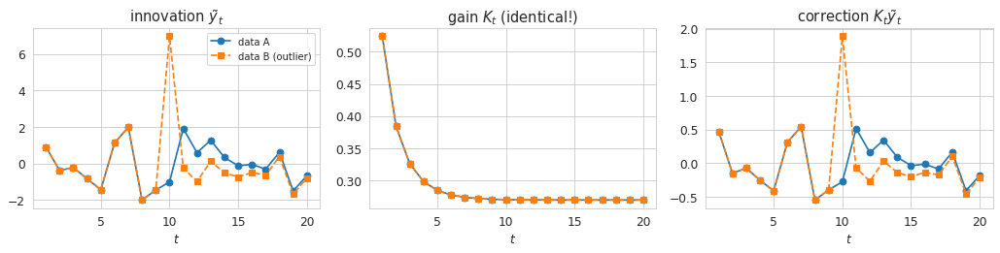

max |K_A - K_B| = 0.0


In [24]:
#@title ▶ Run the experiment (code hidden)
rng = np.random.default_rng(seed)
y_a = np.cumsum(np.sqrt(q)*rng.standard_normal(T)) + np.sqrt(r)*rng.standard_normal(T)
y_b = y_a.copy(); y_b[min(max(t_outlier, 1), T) - 1] += outlier_size
ra, rb = kf_1d(y_a, q=q, r=r), kf_1d(y_b, q=q, r=r)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
tt = np.arange(1, T + 1)
axs[0].plot(tt, ra['innov'], 'o-', label='data A'); axs[0].plot(tt, rb['innov'], 's--', label='data B (outlier)')
axs[0].set_title(r'innovation $\tilde y_t$'); axs[0].legend(fontsize=9)
axs[1].plot(tt, ra['K'], 'o-'); axs[1].plot(tt, rb['K'], 's--'); axs[1].set_title('gain $K_t$ (identical!)')
axs[2].plot(tt, ra['K']*ra['innov'], 'o-'); axs[2].plot(tt, rb['K']*rb['innov'], 's--'); axs[2].set_title(r'correction $K_t\tilde y_t$')
for a in axs: a.set_xlabel('$t$')
plt.tight_layout(); plt.show()
print('max |K_A - K_B| =', np.max(np.abs(ra['K'] - rb['K'])))

> **🔎 What we see.** The outlier produces a huge innovation at `t_outlier` (left), and the gain sequences of the two runs lie exactly on top of each other (middle; the printed difference is 0). The correction $K_t\tilde y_t$ (right) therefore jumps at the outlier, and smaller after-effects follow for a few steps, because the estimate was pulled away and has to come back.
>
> **🎛️ What changes when you change the parameters.**
> - **`outlier_size`** (try 50): the left and right panels scale up; the middle panel does not change at all.
> - **`r` ↑**: smaller gains, so the same outlier does less damage.
> - **`q`**: changes the gain curve, but still identically for both runs.
>
> **💡 Why.** $K_t$ is computed from $\boldsymbol\Sigma_{t|t-1}$, $\mathbf{H}_t$ and $\mathbf{R}_t$ only (slide *The Gain Is a Regression Slope*). A surprise is “answered” with a large correction, never with a different gain. This is also the Kalman filter's weakness against outliers: one bad reading moves the estimate by $K_t\times$(outlier). Adaptive and robust filters *do* react to $\epsilon_t$ (gating outliers, inflating $\mathbf{Q}_t$), but that is an extension of the standard filter.

## Gain Evolution and the Steady-State Filter
Scalar random walk; several filters that differ only in $\sigma_0^2$. Left: variance saw-tooth (prediction adds $q$, update multiplies by $1-K_t$). Right: $K_t$ and the DARE value $K_\infty$ (dashed), $P=\tfrac{q+\sqrt{q^2+4qr}}{2}$, $K_\infty=\tfrac{P}{P+r}$.

In [25]:
#@title ⚙️ Parameters — gain evolution and steady state
#@markdown `q`, `r`: noise variances · `sigma2_0_list`: initial variances, one filter each · `T`: number of steps
q = 0.1                            #@param {type:"number"}
r = 1.0                            #@param {type:"number"}
sigma2_0_list = [0.01, 1.0, 100.0] #@param {type:"raw"}
T = 25                             #@param {type:"integer"}

In [26]:
#@title ▶ Run the simulation (code hidden; double-click to show)
P_inf = (q + np.sqrt(q**2 + 4*q*r))/2; K_inf = P_inf/(P_inf + r)
cols = palette(len(sigma2_0_list))
dummy = np.zeros(T)     # data are irrelevant for variances and gains
runs = [kf_1d(dummy, q=q, r=r, sigma2_0=s) for s in sigma2_0_list]

def sawtooth(run, s20, n):
    xs, ys = [0], [s20]
    for t in range(n):
        xs += [t + 1, t + 1]; ys += [run['s2_pred'][t], run['s2_filt'][t]]
    return np.array(xs), np.array(ys)

allv = np.concatenate([np.r_[s, R_['s2_pred'], R_['s2_filt']] for s, R_ in zip(sigma2_0_list, runs)])
allv = allv[allv > 0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.set_yscale('log'); ax1.set_xlim(0, T); ax1.set_ylim(allv.min()/2, allv.max()*2); ax1.set_xlabel('$t$'); ax1.set_ylabel('variance')
ax1.set_title(r'$\sigma^2_{t|t-1}$ (top of tooth) and $\sigma^2_{t|t}$ (bottom)')
ax2.set_xlim(0, T); ax2.set_ylim(0, 1.02); ax2.set_xlabel('$t$'); ax2.set_ylabel('$K_t$')
ax2.axhline(K_inf, color='k', ls='--', lw=1.5, label=rf'$K_\infty={K_inf:.3f}$ (DARE)')
saws = [ax1.plot([], [], color=c, lw=1.8, label=rf'$\sigma_0^2={s}$')[0] for s, c in zip(sigma2_0_list, cols)]
gains = [ax2.plot([], [], 'o-', color=c, lw=1.8, ms=4, label=rf'$\sigma_0^2={s}$')[0] for s, c in zip(sigma2_0_list, cols)]
ax1.legend(fontsize=9); ax2.legend(fontsize=9)

def update(k):
    n = k + 1
    for run, s, l in zip(runs, sigma2_0_list, saws):
        xs, ys = sawtooth(run, s, n); l.set_data(xs, np.maximum(ys, allv.min()/2))
    for run, l in zip(runs, gains): l.set_data(np.arange(1, n + 1), run['K'][:n])
    return saws + gains

show_anim(animation.FuncAnimation(fig, update, frames=T, interval=250))

> **🔎 What we see.** The filters start far apart (note the log scale): one is very confident, one is moderate, one knows nothing. Within roughly 5–10 steps, all saw-tooth curves merge into the same periodic pattern, and all gains converge to the dashed $K_\infty$ from the DARE. The confident filter's gain *rises* to $K_\infty$; the uncertain filter's gain *falls* to it.
>
> **🎛️ What changes when you change the parameters.**
> - **`q` ↑** (e.g. 1): $K_\infty$ grows (≈0.62 for $q=r=1$) and convergence is faster.
> - **`q` = 0**: $K_\infty=0$. The gains keep decreasing like $1/t$ and never settle at a positive value (a running average).
> - **`r` ↑** (e.g. 10): $K_\infty$ shrinks and the filter needs more steps to converge.
> - **Add more values to `sigma2_0_list`**, e.g. `[1e-4, 0.01, 1, 100, 1e4]`: all of them still converge to the same $K_\infty$.
>
> **💡 Why.** The variance recursion $\sigma^2_{t|t-1} = \frac{\sigma^2_{t-1|t-2}\,r}{\sigma^2_{t-1|t-2}+r}+q$ (the Riccati equation) contains **no data**. It is a deterministic map with a single stable fixed point $P$, which attracts every starting value. In practice, for time-invariant systems you can precompute $K_\infty$ and use the cheaper steady-state filter. $\sigma_0^2$ only shapes the first few steps.

---
# 7. Tuning and Failure Modes
## Initial Conditions: $\boldsymbol\Sigma_0$ and $\boldsymbol\mu_0$
**$\boldsymbol\Sigma_0$:** the truth starts at `z_0_true`, every filter starts at the wrong `mu_0`, and the filters differ only in how much they believe it.

**Predict before you play:** which filter reaches the truth first?

In [27]:
#@title ⚙️ Parameters — initial covariance
#@markdown `z_0_true`: true starting position · `mu_0`: initial guess used by all filters
#@markdown `sigma2_0_list`: initial variance of each filter · `q`, `r`: noise variances (true = assumed) · `T`, `seed`
z_0_true = 5.0                      #@param {type:"number"}
mu_0 = 0.0                          #@param {type:"number"}
sigma2_0_list = [0.01, 1.0, 1000.0] #@param {type:"raw"}
q = 0.05                            #@param {type:"number"}
r = 1.0                             #@param {type:"number"}
T = 40                              #@param {type:"integer"}
seed = 11                           #@param {type:"integer"}

In [28]:
#@title ▶ Run the simulation (code hidden; double-click to show)
rng = np.random.default_rng(seed)
z = z_0_true + np.cumsum(np.sqrt(q)*rng.standard_normal(T))
y = z + np.sqrt(r)*rng.standard_normal(T)
runs = [kf_1d(y, q=q, r=r, mu0=mu_0, sigma2_0=s) for s in sigma2_0_list]
labels = [rf'$\sigma_0^2={s}$  (RMSE {rmse(R_["mu_filt"], z):.2f}, $K_1={R_["K"][0]:.2f}$)' for s, R_ in zip(sigma2_0_list, runs)]
animate_comparison(np.arange(1, T + 1), z, y, [R_['mu_filt'] for R_ in runs], [R_['K'] for R_ in runs],
                   labels, palette(len(runs)), rf'Same data, same wrong $\mu_0={mu_0}$, different $\sigma_0^2$',
                   legend_loc='lower right' if z_0_true > mu_0 else 'upper right')

> **🔎 What we see.** All filters see the same red measurements. The overconfident filter (smallest $\sigma_0^2$) starts with a tiny gain and creeps slowly from $\mu_0$ towards the truth, taking 10–15 steps. The diffuse filter ($\sigma_0^2=1000$) has $K_1\approx1$ and jumps onto the first measurement immediately. In the lower panel, all gains end at the same value. After the transient the estimates are indistinguishable. The legend shows the RMSE; it is largest for the overconfident filter.
>
> **🎛️ What changes when you change the parameters.**
> - **`z_0_true` = `mu_0`** (a correct guess): now the overconfident filter is the *best* at the start. Confidence only pays off when it is justified.
> - **Larger initial error** (e.g. `z_0_true` = 20): the overconfident filter's lag becomes dramatic.
> - **`q` ↑** (e.g. 0.5): even the overconfident filter recovers quickly, because $q$ inflates its variance at every step.
> - **`q` = 0**: the overconfident filter may never fully recover within $T$ steps (its gain decays like $1/t$).
>
> **💡 Why.** At $t=1$, $K_1 = (\sigma_0^2+q)/(\sigma_0^2+q+r)$. A small $\sigma_0^2$ means “my prior is worth many measurements”, so new data are down-weighted until the accumulated $q$ and measurements overwhelm the prior. A large $\sigma_0^2$ means the prior is worth nothing, so the first measurement dominates — the correct behaviour when you really do not know. Because of the Riccati convergence (Section 6, *Gain evolution*), $\boldsymbol{\Sigma}_0$ affects only the transient. **Rule of thumb:** when in doubt, choose $\boldsymbol{\Sigma}_0$ large.

**$\boldsymbol\mu_0$:** filters with $\mu_0\in[-$`mu_0_max`$,+$`mu_0_max`$]$ and the same $\sigma_0^2$ process the same data. Their differences obey $e_t=(1-K_t)F_t\,e_{t-1}$; the lower panel compares the simulated difference with $\mu_{0,\max}\prod_s(1-K_s)$.

In [29]:
#@title ⚙️ Parameters — forgetting the initial mean
#@markdown `mu_0_max`: largest |initial guess| · `n_filters`: number of filters · `sigma2_0`: common initial variance
#@markdown `q`, `r`: noise variances · `T`, `seed`
mu_0_max = 100.0  #@param {type:"number"}
n_filters = 9     #@param {type:"integer"}
sigma2_0 = 1.0    #@param {type:"number"}
q = 0.5           #@param {type:"number"}
r = 4.0           #@param {type:"number"}
T = 40            #@param {type:"integer"}
seed = 4          #@param {type:"integer"}

In [30]:
#@title ▶ Run the simulation (code hidden; double-click to show)
rng = np.random.default_rng(seed)
z = np.cumsum(np.sqrt(q)*rng.standard_normal(T))
y = z + np.sqrt(r)*rng.standard_normal(T)
mu0s = np.linspace(-mu_0_max, mu_0_max, n_filters)
runs = [kf_1d(y, q=q, r=r, mu0=m, sigma2_0=sigma2_0) for m in mu0s]
ref = kf_1d(y, q=q, r=r, mu0=0.0, sigma2_0=sigma2_0)['mu_filt']
diff = np.abs(runs[-1]['mu_filt'] - ref); theory = mu_0_max*np.cumprod(1 - runs[0]['K'])
cmap = plt.cm.coolwarm(np.linspace(0, 1, n_filters))
tt = np.arange(1, T + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})
span = max(mu_0_max, np.abs(y).max())
ax1.set_xlim(0, T); ax1.set_ylim(-1.1*span, 1.1*span); ax1.set_ylabel(r'$\mu_{t|t}$')
ax1.set_title(r'Different $\mu_0$, identical measurements: the initial state error is washed out')
l_tr, = ax1.plot([], [], color=C_TRUE, lw=2.5, label='truth'); l_y, = ax1.plot([], [], '.', color=C_LIK, alpha=0.5, label='$y_t$')
lines = [ax1.plot([0], [m], color=c, lw=1.8)[0] for m, c in zip(mu0s, cmap)]
ax1.legend(loc='upper right')
lo = max(min(theory.min(), diff[diff > 0].min() if np.any(diff > 0) else 1e-8)/5, 1e-12)
ax2.set_yscale('log'); ax2.set_ylim(lo, 2*mu_0_max); ax2.set_xlabel('$t$')
ax2.set_ylabel('|difference|')
l_d, = ax2.plot([], [], 'o', color=cmap[-1], ms=4, label=r'simulated $|\mu^{(\max)}_{t|t}-\mu^{(0)}_{t|t}|$')
l_th, = ax2.plot([], [], '--', color='k', label=r'$\mu_{0,\max}\prod_s(1-K_s)$')
ax2.legend(loc='upper right', fontsize=9)

def update(k):
    n = k + 1
    l_tr.set_data(np.r_[0, tt[:n]], np.r_[0, z[:n]]); l_y.set_data(tt[:n], y[:n])
    for l, R_, m in zip(lines, runs, mu0s): l.set_data(np.r_[0, tt[:n]], np.r_[m, R_['mu_filt'][:n]])
    l_d.set_data(tt[:n], np.maximum(diff[:n], lo)); l_th.set_data(tt[:n], theory[:n])
    return lines + [l_tr, l_y, l_d, l_th]

show_anim(animation.FuncAnimation(fig, update, frames=T, interval=150))

> **🔎 What we see.** The fan of estimates, starting from $\pm100$, collapses onto one trajectory within about 15 steps. After that, all filters give the same answer and follow the truth. On the log scale the difference falls along a straight line, i.e. **geometrically**, and the simulated points sit exactly on the formula. After 40 steps an initial disagreement of 100 has shrunk to about $10^{-4}$.
>
> **🎛️ What changes when you change the parameters.**
> - **`sigma2_0` ↑** (e.g. 100): $K_1\approx1$ and the fan collapses in a single step.
> - **`sigma2_0` ↓** (e.g. 0.01): the filters trust their wrong guesses and forgetting is slow.
> - **`q` ↓** (e.g. 0.01): $K_\infty$ is small, so the line in the lower panel becomes much flatter.
> - **`r` ↑**: smaller gains, also slower forgetting.
> - **`mu_0_max`**: only rescales the picture; the *rate* of forgetting does not change.
>
> **💡 Why.** The filters differ only in the initial mean, and the update is linear in the mean. The difference between any two filters therefore obeys $e_t = (1-K_t)F_t\,e_{t-1}$, regardless of the data. Since $0<1-K_t<1$, every step removes the fraction $K_t$ of the remaining error. Caveat: this assumes a correct model and $K_\infty > 0$. With $\mathbf{Q}_t = \mathbf{0}$ the product only decays like $1/t$, and a bad $\boldsymbol{\mu}_0$ lingers.

## Choosing $\mathbf R_t$ and $\mathbf Q_t$
**$\mathbf R_t$:** random-walk truth with true measurement variance `r_true`; the filters assume `factor` × `r_true`.

In [31]:
#@title ⚙️ Parameters — wrong measurement noise
#@markdown `q`: process-noise variance (true = assumed) · `r_true`: true sensor variance
#@markdown `r_factors`: assumed $r_t$ = factor × `r_true`, one filter per factor · `T`, `seed`
q = 0.1                       #@param {type:"number"}
r_true = 1.0                  #@param {type:"number"}
r_factors = [0.01, 1.0, 100.0] #@param {type:"raw"}
T = 60                        #@param {type:"integer"}
seed = 21                     #@param {type:"integer"}

In [32]:
#@title ▶ Run the simulation (code hidden; double-click to show)
rng = np.random.default_rng(seed)
z = np.cumsum(np.sqrt(q)*rng.standard_normal(T))
y = z + np.sqrt(r_true)*rng.standard_normal(T)
runs = [kf_1d(y, q=q, r=f*r_true, sigma2_0=1.0) for f in r_factors]
labels = [rf'$r_t={f:g}\,r_{{true}}$  (RMSE {rmse(R_["mu_filt"], z):.2f}, $K_\infty\approx{R_["K"][-1]:.2f}$)' for f, R_ in zip(r_factors, runs)]
print(f'RMSE of raw measurements: {rmse(y, z):.2f}')
animate_comparison(np.arange(1, T + 1), z, y, [R_['mu_filt'] for R_ in runs], [R_['K'] for R_ in runs],
                   labels, palette(len(runs)), rf'Assumed measurement noise vs. true $r_{{true}}={r_true}$')

RMSE of raw measurements: 0.89


> **🔎 What we see.** The filter that assumes a tiny $r_t$ has $K_t\approx0.9$. It copies the red dots, including their noise, so its RMSE is close to that of the raw measurements. The filter that assumes a huge $r_t$ has $K_t\approx0.03$. It is very smooth but lags far behind every move of the truth. The correctly tuned filter has a moderate gain (≈0.27) and the smallest RMSE.
>
> **🎛️ What changes when you change the parameters.**
> - **Factors closer to 1** (e.g. `[0.3, 1, 3]`): the RMSE values move closer together. The optimum is fairly flat, so a factor-of-2 error in $r_t$ costs little.
> - **`q` ↑**: the truth moves more, so the over-smoothing filter (large factor) suffers even more.
> - **`q` ↓** (e.g. 0.001): the truth is nearly constant and heavy smoothing becomes almost harmless.
>
> **💡 Why.** The assumed $r_t$ enters only through $K_t$. An underestimated $r_t$ makes the filter trust each noisy reading too much: low bias, high variance. An overestimated $r_t$ makes it average over too long a window: low variance, high bias (lag). The true $r$ gives the MMSE balance. The filter's own $\sigma^2_{t|t}$ is wrong in both mis-specified cases: too optimistic in one, too pessimistic in the other.

**$\mathbf Q_t$:** 1D constant-velocity model with $\mathbf Q_t=q_a\begin{bmatrix}\Delta t^4/4&\Delta t^3/2\\ \Delta t^3/2&\Delta t^2\end{bmatrix}$; the target changes velocity at `t_maneuver` (not expected by the model). Only position is measured; the middle panel shows the hidden velocity estimate.

In [33]:
#@title ⚙️ Parameters — wrong process noise (manoeuvre)
#@markdown `q_a_list`: process-noise intensities, one filter each · `r_meas`: measurement variance
#@markdown `t_maneuver`, `v_before`, `v_after`: the manoeuvre · `T`, `seed`
q_a_list = [1e-4, 0.05, 5.0]  #@param {type:"raw"}
r_meas = 4.0                  #@param {type:"number"}
t_maneuver = 30               #@param {type:"integer"}
v_before = 1.0                #@param {type:"number"}
v_after = -1.5                #@param {type:"number"}
T = 80                        #@param {type:"integer"}
seed = 8                      #@param {type:"integer"}

In [34]:
#@title ▶ Run the simulation (code hidden; double-click to show)
dt = 1.0
F_cv = np.array([[1, dt], [0, 1]]); H_cv = np.array([[1.0, 0.0]])
Qshape = np.array([[dt**4/4, dt**3/2], [dt**3/2, dt**2]])
pos, vel, y = maneuver_scenario(T=T, r=r_meas, seed=seed, t_maneuver=t_maneuver, v_before=v_before, v_after=v_after)
runs = [run_kf(KalmanFilter(F_cv, H_cv, qa*Qshape, np.array([[r_meas]])), y, np.array([0.0, 0.0]), np.diag([10.0, 4.0]))
        for qa in q_a_list]
labels = [rf'$q_a={qa:g}$  (RMSE pos {rmse(R_["mu_filt"][:, 0], pos):.2f})' for qa, R_ in zip(q_a_list, runs)]
animate_comparison(np.arange(1, T + 1), pos, y, [R_['mu_filt'][:, 0] for R_ in runs], [R_['K'][:, 0, 0] for R_ in runs],
                   labels, palette(len(runs)), rf'Process noise $\mathbf{{Q}}_t$ and a manoeuvre at $t={t_maneuver}$',
                   gain_label=r'$K_t$ (position)', mid=(vel, [R_['mu_filt'][:, 1] for R_ in runs], 'velocity'),
                   legend_loc='lower left')

> **🔎 What we see.** Before the manoeuvre all filters do well, and the smallest $q_a$ is even the smoothest. After the manoeuvre the small-$q_a$ filter keeps believing the old velocity. Its velocity estimate (middle panel) turns around only very slowly, and its position estimate overshoots by many units. The large-$q_a$ filter reacts within a couple of steps, but its velocity estimate is noisy throughout. The intermediate value gives the best overall RMSE. The bottom panel explains the behaviour: the small-$q_a$ gain has decayed close to zero, while the large-$q_a$ gain stays near 0.8.
>
> **🎛️ What changes when you change the parameters.**
> - **`v_after` = `v_before`** (no manoeuvre): the smallest $q_a$ now wins. It is the right model when nothing changes.
> - **More violent manoeuvre** (e.g. `v_after` = −5): the lag of the small-$q_a$ filter grows dramatically.
> - **`r_meas` ↑** (e.g. 25): every filter becomes slower, and the noise of the large-$q_a$ filter becomes more visible.
> - **Fill `q_a_list` with a range**, e.g. `[1e-3, 1e-2, 0.1, 1]`: you can locate the best value for this scenario by its RMSE.
>
> **💡 Why.** $\mathbf{Q}_t$ tells the filter how much the state can change between steps that the model does not explain. A small $\mathbf{Q}_t$ means “velocity is (nearly) constant”: $\boldsymbol\Sigma$ and $\mathbf{K}_t$ shrink, so the filter averages over a long window and cannot follow a change. A large $\mathbf{Q}_t$ keeps the window short: responsive, but noisy. $\mathbf{Q}_t$ is therefore a **bandwidth knob**. Real targets manoeuvre unpredictably, so $\mathbf{Q}_t$ is usually tuned on recorded data or monitored with the innovation diagnostics below.

## Innovations, Consistency and Divergence
Same manoeuvre. One filter uses `q_a_good`, the other `q_a_bad` (default 0 = perfect-model assumption). Panels: estimate with its claimed $\pm2\sigma_{t|t}$ band; innovations with $\pm2\sqrt{S_t}$; NIS $\epsilon_t=\tilde y_t^2/S_t$ with the 95% $\chi^2_1$ line.

In [35]:
#@title ⚙️ Parameters — filter divergence
#@markdown `q_a_good`, `q_a_bad`: process-noise intensities of the two filters · `r_meas`: measurement variance
#@markdown `t_maneuver`, `v_before`, `v_after`: the manoeuvre · `T`, `seed`
q_a_good = 0.05   #@param {type:"number"}
q_a_bad = 0.0     #@param {type:"number"}
r_meas = 4.0      #@param {type:"number"}
t_maneuver = 30   #@param {type:"integer"}
v_before = 1.0    #@param {type:"number"}
v_after = -1.5    #@param {type:"number"}
T = 80            #@param {type:"integer"}
seed = 8          #@param {type:"integer"}

In [36]:
#@title ▶ Run the simulation (code hidden; double-click to show)
dt = 1.0
F_cv = np.array([[1, dt], [0, 1]]); H_cv = np.array([[1.0, 0.0]])
Qshape = np.array([[dt**4/4, dt**3/2], [dt**3/2, dt**2]])
pos, vel, y = maneuver_scenario(T=T, r=r_meas, seed=seed, t_maneuver=t_maneuver, v_before=v_before, v_after=v_after)
specs = [(q_a_good, 'tab:green', rf'$q_a={q_a_good:g}$'), (q_a_bad, 'tab:purple', rf'$q_a={q_a_bad:g}$')]
runs = [run_kf(KalmanFilter(F_cv, H_cv, qa*Qshape, np.array([[r_meas]])), y, np.array([0.0, 0.0]), np.diag([10.0, 4.0])) for qa, _, _ in specs]
tt = np.arange(1, T + 1)
nis = [R_['innov'][:, 0]**2/R_['S'][:, 0, 0] for R_ in runs]
for (qa, _, _), e in zip(specs, nis):
    print(f'q_a = {qa:g}:  fraction of NIS above the 95% line = {np.mean(e > chi2.ppf(0.95, 1)):.2f}  (should be about 0.05)')
imax = 1.15*max(np.abs(np.r_[runs[0]['innov'][:, 0], runs[1]['innov'][:, 0]]).max(), 2*np.sqrt(max(runs[0]['S'].max(), runs[1]['S'].max())))
fig, axs = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True, gridspec_kw={'height_ratios': [2, 1.4, 1.2]})
axs[0].set_xlim(0, T + 1); axs[0].set_ylim(y.min() - 3, y.max() + 3); axs[0].set_ylabel('position')
l_tr, = axs[0].plot([], [], color=C_TRUE, lw=2, label='truth'); l_y, = axs[0].plot([], [], '.', color=C_LIK, alpha=0.5, label='$y_t$')
l_est = [axs[0].plot([], [], color=c, lw=2, label=lab)[0] for _, c, lab in specs]
axs[0].legend(loc='lower left', fontsize=9)
l_inn = [axs[1].plot([], [], 'o', color=c, ms=3.5)[0] for _, c, _ in specs]
l_bnd = [axs[1].plot([], [], '-', color=c, lw=1)[0] for _, c, _ in specs] + [axs[1].plot([], [], '-', color=c, lw=1)[0] for _, c, _ in specs]
axs[1].set_ylim(-imax, imax); axs[1].set_ylabel(r'$\tilde y_t$  and  $\pm2\sqrt{S_t}$')
axs[2].set_yscale('log'); axs[2].set_ylim(1e-3, max(1e3, 3*max(e.max() for e in nis))); axs[2].axhline(chi2.ppf(0.95, 1), color='k', ls='--', lw=1)
axs[2].text(1, chi2.ppf(0.95, 1)*1.3, r'95% $\chi^2_1$', fontsize=9)
l_nis = [axs[2].plot([], [], 'o-', color=c, ms=3, lw=1)[0] for _, c, _ in specs]
axs[2].set_ylabel(r'NIS $\epsilon_t$'); axs[2].set_xlabel('$t$')
fills = []

def update(k):
    n = k + 1
    for f in fills: f.remove()
    fills.clear()
    l_tr.set_data(tt[:n], pos[:n]); l_y.set_data(tt[:n], y[:n])
    for i, R_ in enumerate(runs):
        m = R_['mu_filt'][:n, 0]; s = 2*np.sqrt(R_['Sig_filt'][:n, 0, 0])
        l_est[i].set_data(tt[:n], m)
        fills.append(axs[0].fill_between(tt[:n], m - s, m + s, color=specs[i][1], alpha=0.2))
        bnd = 2*np.sqrt(R_['S'][:n, 0, 0])
        l_inn[i].set_data(tt[:n], R_['innov'][:n, 0]); l_bnd[i].set_data(tt[:n], bnd); l_bnd[i + 2].set_data(tt[:n], -bnd)
        l_nis[i].set_data(tt[:n], np.maximum(nis[i][:n], 1e-3))
    return []

show_anim(animation.FuncAnimation(fig, update, frames=T, interval=110))

q_a = 0.05:  fraction of NIS above the 95% line = 0.03  (should be about 0.05)
q_a = 0:  fraction of NIS above the 95% line = 0.59  (should be about 0.05)


> **🔎 What we see.** Before the manoeuvre both filters look fine. The $q_a=0$ filter even has the narrower band, because it believes its model is perfect. Its claimed uncertainty keeps shrinking and its gain goes to zero. After the manoeuvre its estimate drifts away from the truth, yet its shaded band stays thin: it is **confidently wrong**. Its innovations walk out of the $\pm2\sqrt{S_t}$ band and stay out, and its NIS sits one to two orders of magnitude above the 95% line. The printout shows that this happens in a large fraction of the steps, not the expected 5%. The well-tuned filter's innovations stay inside the band apart from a short burst at the manoeuvre.
>
> **🎛️ What changes when you change the parameters.**
> - **`v_after` = `v_before`** (no manoeuvre): the $q_a=0$ filter is perfectly consistent. A model is only “wrong” when reality violates it.
> - **`q_a_bad` = 0.001**: a tiny bit of process noise keeps the gain above zero. The filter still lags, but it eventually recovers instead of diverging.
> - **`t_maneuver` later** (e.g. 60): the $q_a=0$ filter has become even more confident by then, so the divergence is sharper.
> - **`r_meas` ↑**: the bands widen and the divergence becomes harder to see in each innovation, but the NIS statistics still reveal it.
>
> **💡 Why.** With $\mathbf{Q}_t=\mathbf{0}$ the covariance $\boldsymbol\Sigma_{t|t}\to\mathbf{0}$, so $\mathbf{K}_t\to\mathbf{0}$ and new measurements are ignored. The filter then cannot follow any unmodelled change. Because $\mathbf{S}_t$ is computed from the filter's own (too small) covariance, real errors appear as innovations that are far larger than the filter predicts. In real systems the truth is unknown, so **innovation monitoring is the only real-time check**. In practice: about 5% of innovations should fall outside $\pm2\sqrt{S_t}$, the average NIS should be about $n_y$, and the innovations should be uncorrelated. This is the **consistency** property on the “Key properties” slide.

---
# 8. Examples
## Example 2: Constant Velocity Model (2D Tracking)
$\mathbf z_t=[x_t,\dot x_t,y_t,\dot y_t]^\top$, constant-velocity $\mathbf F_t$ and $\mathbf Q_t$ (as on the slide), only positions measured, $\mathbf R_t=\sigma_r^2\mathbf I$. The aircraft flies a circle; the filter starts with zero velocity. Blue dashed: predicted $2\sigma$ position ellipse; green: filtered; red: one measurement. Arrows: true (black) and estimated (green) velocity.

In [47]:
#@title ⚙️ Parameters — aircraft tracking
#@markdown Truth: `radius`, `omega` (rad/s), `dt_2d` (s), `T_2d` steps · Filter: `q_2d` (process noise), `sigma_r` (measurement std, also used to simulate)
#@markdown `sigma_v0`: initial velocity std · `frame_step`: animate every n-th step · `seed`
radius = 50.0     #@param {type:"number"}
omega = 0.1       #@param {type:"number"}
dt_2d = 0.5       #@param {type:"number"}
T_2d = 200        #@param {type:"integer"}
q_2d = 0.5        #@param {type:"number"}
sigma_r = 5.0     #@param {type:"number"}
sigma_v0 = 5.0    #@param {type:"number"}
frame_step = 3    #@param {type:"integer"}
seed = 42         #@param {type:"integer"}

In [48]:
#@title ▶ Run the simulation (code hidden; double-click to show)
F_2d = np.array([[1, dt_2d, 0, 0], [0, 1, 0, 0], [0, 0, 1, dt_2d], [0, 0, 0, 1]])
H_2d = np.array([[1, 0, 0, 0], [0, 0, 1, 0]])
Qb = np.array([[dt_2d**4/4, dt_2d**3/2], [dt_2d**3/2, dt_2d**2]])
Q_2d = q_2d*np.block([[Qb, np.zeros((2, 2))], [np.zeros((2, 2)), Qb]]); R_2d = sigma_r**2*np.eye(2)
rng = np.random.default_rng(seed)
ang = omega*np.arange(T_2d)*dt_2d
z_true_2d = np.c_[radius*np.cos(ang), -radius*omega*np.sin(ang), radius*np.sin(ang), radius*omega*np.cos(ang)]
y_obs_2d = z_true_2d[:, [0, 2]] + sigma_r*rng.standard_normal((T_2d, 2))
mu0_2d = np.array([y_obs_2d[0, 0], 0.0, y_obs_2d[0, 1], 0.0])
Sig0_2d = np.diag([sigma_r**2, sigma_v0**2, sigma_r**2, sigma_v0**2])
res2 = run_kf(KalmanFilter(F_2d, H_2d, Q_2d, R_2d), y_obs_2d, mu0_2d, Sig0_2d)
ip = [0, 2]
speed_true = np.hypot(z_true_2d[:, 1], z_true_2d[:, 3]); speed_est = np.hypot(res2['mu_filt'][:, 1], res2['mu_filt'][:, 3])
tt = np.arange(T_2d)*dt_2d
print(f"position RMSE: measurements {rmse(y_obs_2d, z_true_2d[:, ip]):.2f}, filter {rmse(res2['mu_filt'][:, ip], z_true_2d[:, ip]):.2f};  "
      f"velocity RMSE (after 20 steps) {rmse(res2['mu_filt'][20:, [1, 3]], z_true_2d[20:, [1, 3]]):.2f}")

L = 1.25*radius + 3*sigma_r
fig = plt.figure(figsize=(12.5, 6.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], hspace=0.35, wspace=0.22)
ax = fig.add_subplot(gs[:, 0]); axs_ = fig.add_subplot(gs[0, 1]); axk = fig.add_subplot(gs[1, 1])
ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_aspect('equal'); ax.set_xlabel('$x$'); ax.set_ylabel('$y$')
l_tr, = ax.plot([], [], color=C_TRUE, lw=1.5, alpha=0.6, label='truth')
l_ms, = ax.plot([], [], '.', color=C_LIK, alpha=0.35, label=r'measurements $\mathbf{y}_t$')
l_es, = ax.plot([], [], color=C_POST, lw=2, label=r'estimate $\mu_{t|t}$')
l_ep, = ax.plot([], [], '--', color=C_PRIOR, lw=1.5); l_ef, = ax.plot([], [], color=C_POST, lw=2.5)
l_er, = ax.plot([], [], color=C_LIK, lw=1, alpha=0.7)
qscale = max(radius*omega, 1e-3)/(0.3*radius)   # true velocity arrow = 30% of the radius
q_true = ax.quiver([0], [0], [0], [0], color=C_TRUE, angles='xy', scale_units='xy', scale=qscale, width=0.005)
q_est = ax.quiver([0], [0], [0], [0], color=C_POST, angles='xy', scale_units='xy', scale=qscale, width=0.005)
ax.legend(loc='upper right', fontsize=8)
axs_.set_xlim(0, tt[-1]); axs_.set_ylim(0, 2*max(speed_true.max(), 1e-3)); axs_.set_ylabel('speed')
axs_.plot(tt, speed_true, '--', color=C_TRUE, lw=1, label='true speed')
l_sp, = axs_.plot([], [], color=C_POST, lw=2, label='estimated (never measured!)'); axs_.legend(fontsize=8, loc='lower right')
axk.set_xlim(0, tt[-1]); axk.set_ylim(0, 1); axk.set_xlabel('time'); axk.set_ylabel('gain')
l_k0, = axk.plot([], [], color='tab:purple', lw=2, label=r'$K_t[x, x]$ (position)')
l_k1, = axk.plot([], [], color='tab:brown', lw=2, label=r'$K_t[\dot x, x]$ (velocity)'); axk.legend(fontsize=8)
frames = list(range(1, T_2d, max(1, frame_step))) + [T_2d - 1]*8
ttl = ax.set_title('')

def update(k):
    n = frames[k]
    l_tr.set_data(z_true_2d[:n+1, 0], z_true_2d[:n+1, 2]); l_ms.set_data(y_obs_2d[:n+1, 0], y_obs_2d[:n+1, 1])
    l_es.set_data(res2['mu_filt'][:n+1, 0], res2['mu_filt'][:n+1, 2])
    mp = res2['mu_pred'][n][ip]; Sp = res2['Sig_pred'][n][np.ix_(ip, ip)]
    mf = res2['mu_filt'][n][ip]; Sf = res2['Sig_filt'][n][np.ix_(ip, ip)]
    e = ellipse_xy(mp, Sp); l_ep.set_data(e[0], e[1]); e = ellipse_xy(mf, Sf); l_ef.set_data(e[0], e[1])
    e = ellipse_xy(y_obs_2d[n], R_2d); l_er.set_data(e[0], e[1])
    q_true.set_offsets([[z_true_2d[n, 0], z_true_2d[n, 2]]]); q_true.set_UVC([z_true_2d[n, 1]], [z_true_2d[n, 3]])
    q_est.set_offsets([mf]); q_est.set_UVC([res2['mu_filt'][n, 1]], [res2['mu_filt'][n, 3]])
    l_sp.set_data(tt[:n+1], speed_est[:n+1])
    l_k0.set_data(tt[:n+1], res2['K'][:n+1, 0, 0]); l_k1.set_data(tt[:n+1], res2['K'][:n+1, 1, 0])
    ttl.set_text(f'time = {tt[n]:.1f}')
    return []

show_anim(animation.FuncAnimation(fig, update, frames=len(frames), interval=100))

position RMSE: measurements 4.76, filter 2.96;  velocity RMSE (after 20 steps) 1.36


> **🔎 What we see.** The green track follows the circle much more closely than the red measurement cloud (see the printed RMSE). The green filtered ellipse is much smaller than the red single-measurement circle, and the blue predicted ellipse is slightly larger than the green one. The speed estimate starts at 0 (the filter is told nothing about velocity) and within a few seconds settles around the true speed, fluctuating around it. Both gains drop quickly and then stay constant (steady state). The velocity gain is much smaller than the position gain, but it is not zero.
>
> **🎛️ What changes when you change the parameters.**
> - **`q_2d` ↓** (e.g. 0.01): a smoother track and a smoother speed estimate, but the estimate lags behind the turn and drifts outside the true circle (the model expects straight-line motion, so it keeps overshooting tangentially), and the speed settles too low.
> - **`q_2d` ↑** (e.g. 10): the estimate follows the noisy measurements; the speed estimate becomes very noisy.
> - **`omega` ↑** (e.g. 0.3, a tighter turn): larger acceleration ($r\omega^2$), so the same `q_2d` is now too small and the lag becomes visible.
> - **`sigma_r` ↓** (e.g. 1): better measurements, so all ellipses shrink and the velocity converges faster.
> - **`sigma_v0` ↓** (e.g. 0.1) while the true speed is 5: the filter is sure the aircraft is standing still, so the speed estimate needs much longer to grow.
>
> **💡 Why.** Velocity is never measured, but it is linked to position by $\mathbf{F}_t$: $x_{t+1} = x_t + \Delta t\,\dot x_t$. The prediction step correlates position and velocity (Section 5), so the velocity entries of $\mathbf{K}_t$ are nonzero (they are proportional to the position–velocity cross-covariance) and position innovations correct velocity. A consistent drift of the measurements ahead of the prediction is interpreted as “we are faster than we thought”. Because a circle is not constant-velocity motion, $\mathbf{Q}_t$ must be large enough to absorb the centripetal acceleration. That is why the right `q_2d` depends on `omega`.

**Interactive tuner:** same truth and measurements; sliders set the filter's $q$, measurement standard deviation and initial velocity uncertainty.

In [39]:
#@title ▶ Interactive aircraft tuner (sliders)
def tune_2d(q=0.5, sigma_r_filter=5.0, sigma_v0_filter=5.0):
    Qt = q*np.block([[Qb, np.zeros((2, 2))], [np.zeros((2, 2)), Qb]]); Rt = sigma_r_filter**2*np.eye(2)
    S0 = np.diag([sigma_r_filter**2, sigma_v0_filter**2, sigma_r_filter**2, sigma_v0_filter**2])
    rr = run_kf(KalmanFilter(F_2d, H_2d, Qt, Rt), y_obs_2d, mu0_2d, S0)
    ep = rmse(rr['mu_filt'][20:, ip], z_true_2d[20:, ip]); ev = rmse(rr['mu_filt'][20:, [1, 3]], z_true_2d[20:, [1, 3]])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
    a1.plot(z_true_2d[:, 0], z_true_2d[:, 2], 'k', lw=1.5, label='truth')
    a1.plot(y_obs_2d[:, 0], y_obs_2d[:, 1], '.', color=C_LIK, alpha=0.3, label='measurements')
    a1.plot(rr['mu_filt'][:, 0], rr['mu_filt'][:, 2], color=C_POST, lw=2, label='estimate'); a1.set_aspect('equal'); a1.legend(fontsize=8)
    a2.plot(tt, speed_true, 'k--', label='true speed'); a2.plot(tt, np.hypot(rr['mu_filt'][:, 1], rr['mu_filt'][:, 3]), color=C_POST, label='estimated speed')
    a2.set_ylim(0, 2.5*speed_true.max()); a2.set_xlabel('time'); a2.legend(fontsize=8)
    fig.suptitle(f'position RMSE = {ep:.2f}    velocity RMSE = {ev:.2f}'); plt.show()

if HAS_WIDGETS:
    interact(tune_2d,
             q=FloatLogSlider(value=q_2d, base=10, min=-4, max=2, step=0.1, continuous_update=False),
             sigma_r_filter=FloatLogSlider(value=sigma_r, base=10, min=-0.5, max=1.7, step=0.05, continuous_update=False),
             sigma_v0_filter=FloatLogSlider(value=sigma_v0, base=10, min=-1, max=1.5, step=0.1, continuous_update=False))
else:
    tune_2d()

interactive(children=(FloatLogSlider(value=0.5, continuous_update=False, description='q', max=2.0, min=-4.0), …

> **🔎 What we see.** With the default sliders you get the same result as the animation. Moving `q` traces out a U-shaped RMSE curve, and the best value is close to where the process noise matches the true centripetal acceleration.
>
> **🎛️ What changes when you change the parameters.**
> - **Very small `q`**: the estimate lags the turn and drifts away from the true circle, and the speed estimate settles too low.
> - **Very large `q`**: the track is as ragged as the measurements, and the velocity RMSE explodes.
> - **`sigma_r_filter` ≠ true `sigma_r`**: this acts like the wrong-$\mathbf{R}_t$ experiment in 6.3.
> - **`sigma_v0_filter`**: affects only the first seconds.
>
> **💡 Why.** `q` and `sigma_r_filter` together set the steady-state gain, i.e. the filter bandwidth, as in Sections 6.3–6.4. The best setting balances noise suppression against the ability to follow the turn. Only the ratio of $q$ to $\sigma_r^2$ matters for the gain; their absolute size sets how wide the filter believes its uncertainty is.

## Example 3: Sensor Fusion
Two radars, accurate in range (`s_range`) and poor in cross-range (`s_cross`); radar 2 rotates around the target. Fused (flat prior): $\boldsymbol\Sigma_{t|t}^{-1}=\mathbf R^{(1)\,-1}+\mathbf R^{(2)\,-1}$.

In [40]:
#@title ⚙️ Parameters — sensor fusion
#@markdown `s_range`, `s_cross`: radar standard deviations along / across the line of sight · `seed`
s_range = 0.6   #@param {type:"number"}
s_cross = 3.0   #@param {type:"number"}
seed = 9        #@param {type:"integer"}

In [41]:
#@title ▶ Run the simulation (code hidden; double-click to show)
def radar_cov(theta):
    u = np.array([np.cos(theta), np.sin(theta)]); v = np.array([-np.sin(theta), np.cos(theta)])
    return s_range**2*np.outer(u, u) + s_cross**2*np.outer(v, v)

z_tgt = np.array([0.0, 0.0])
rng = np.random.default_rng(seed)
e1, e2 = rng.standard_normal(2), rng.standard_normal(2)
R1 = radar_cov(0.0)
thetas = np.r_[np.linspace(0, np.pi, 70), [np.pi]*6]
L = max(s_cross, s_range)*(2.4 + np.abs(np.r_[e1, e2]).max())
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_aspect('equal')
l1, = ax.plot([], [], color='tab:orange', lw=2, label='radar 1 ($2\\sigma$)'); l2, = ax.plot([], [], color='tab:purple', lw=2, label='radar 2 ($2\\sigma$)')
lf, = ax.plot([], [], color=C_POST, lw=3, label='fused $2\\sigma$')
m1, = ax.plot([], [], 'o', color='tab:orange'); m2, = ax.plot([], [], 'o', color='tab:purple'); mf, = ax.plot([], [], 'o', color=C_POST, ms=8)
ax.plot(*z_tgt, '*', color=C_TRUE, ms=15, label='target')
ray = ax.plot([], [], ':', color='tab:purple')[0]; ax.plot([-L, 0], [0, 0], ':', color='tab:orange')
ax.legend(loc='upper right', fontsize=9)
txt = ax.text(0.02, 0.02, '', transform=ax.transAxes, family='monospace', fontsize=10, bbox=dict(fc='white', alpha=0.85))

def update(k):
    th = thetas[k]; R2 = radar_cov(th)
    y1 = z_tgt + np.linalg.cholesky(R1) @ e1; y2 = z_tgt + np.linalg.cholesky(R2) @ e2
    Sf = np.linalg.inv(np.linalg.inv(R1) + np.linalg.inv(R2)); muf = Sf @ (np.linalg.solve(R1, y1) + np.linalg.solve(R2, y2))
    for line, (m, C) in zip([l1, l2, lf], [(y1, R1), (y2, R2), (muf, Sf)]):
        e = ellipse_xy(m, C); line.set_data(e[0], e[1])
    m1.set_data([y1[0]], [y1[1]]); m2.set_data([y2[0]], [y2[1]]); mf.set_data([muf[0]], [muf[1]])
    ray.set_data([-L*np.cos(th), 0], [-L*np.sin(th), 0])
    a = lambda C: np.sqrt(np.linalg.det(C))
    txt.set_text(f'angle between radars = {np.degrees(th):5.1f} deg\narea ~ sqrt(det): R1 {a(R1):.2f}  R2 {a(R2):.2f}  fused {a(Sf):.2f}')
    return l1, l2, lf, m1, m2, mf, ray, txt

show_anim(animation.FuncAnimation(fig, update, frames=len(thetas), interval=90))

> **🔎 What we see.** Each radar alone gives a long, thin ellipse across its line of sight. The green fused ellipse is always contained in the overlap of the two. When both radars look from the same direction (0° and 180°), the fused ellipse is only $\sqrt2$ smaller and keeps the same elongated shape. At 90° it becomes small in *every* direction: with the default values the printed area drops from 1.8 (each radar) to about 0.35.
>
> **🎛️ What changes when you change the parameters.**
> - **`s_cross` = `s_range`** (circular sensors): the geometry no longer matters; fusion always gives a $\sqrt2$ smaller circle.
> - **`s_cross` ≫ `s_range`** (e.g. 10 vs 0.3): at 0° fusion barely helps; at 90° the improvement is dramatic. This is why radar networks and GPS rely on satellites spread across the sky (geometric dilution of precision).
> - **`seed`**: changes the measurement errors and thus where the ellipses sit, but not their shapes.
>
> **💡 Why.** Precisions add: $\boldsymbol\Sigma^{-1}_{\text{fused}} = \mathbf{R}^{(1)-1} + \mathbf{R}^{(2)-1}$. Each sensor contributes information mainly along its accurate direction. If the accurate directions are aligned, the information piles up in one direction only. If they are perpendicular, every direction gets one accurate sensor. The Kalman update does this weighting automatically; the cell below confirms that processing the two radars one after the other gives exactly the same answer as the stacked update.

In [42]:
#@title ⚙️ Parameters — sequential vs. stacked update check
#@markdown `theta_2_deg`: viewing angle of radar 2 relative to radar 1 (degrees)
theta_2_deg = 60.0  #@param {type:"number"}

In [43]:
#@title ▶ Run the check (code hidden)
mu0f, S0f = np.zeros(2), 100.0*np.eye(2)
R1 = radar_cov(0.0); R2 = radar_cov(np.radians(theta_2_deg))
y1, y2 = np.array([0.3, -1.0]), np.array([-0.5, 0.8])
def upd(mu, S, y, Hm, Rm):
    K = S @ Hm.T @ np.linalg.inv(Hm @ S @ Hm.T + Rm); return mu + K @ (y - Hm @ mu), S - K @ Hm @ S
m_a, S_a = upd(*upd(mu0f, S0f, y1, np.eye(2), R1), y2, np.eye(2), R2)
m_b, S_b = upd(mu0f, S0f, np.r_[y1, y2], np.vstack([np.eye(2), np.eye(2)]), np.block([[R1, np.zeros((2, 2))], [np.zeros((2, 2)), R2]]))
print('sequential mean', m_a.round(4), '   stacked mean', m_b.round(4))
print('max |Sigma_seq - Sigma_stacked| =', np.abs(S_a - S_b).max())

sequential mean [0.2866 0.2999]    stacked mean [0.2866 0.2999]
max |Sigma_seq - Sigma_stacked| = 6.838973831690964e-14


> **🔎 What we see.** The two means agree to all printed digits, and the covariance difference is at the level of floating-point round-off.
>
> **🎛️ What changes when you change the parameters.**
> - **Any `theta_2_deg`**: the agreement always holds; only the numbers themselves change.
>
> **💡 Why.** Measurements with independent noise can be processed one at a time, in any order. The posterior after the first radar acts as the prior for the second. This is the same recursion as over time, which is why a Kalman filter can fuse sensors that report asynchronously, at different rates.